# Perbandingan YOLOv11s vs SSD300-VGG16 untuk Deteksi Kardiomegali pada Citra X-Ray Thoraks

**Kaggle Notebook — Revisi Sidang (Minor)**

Notebook ini merupakan konversi pipeline lokal ke lingkungan **Kaggle Notebook**, dengan tambahan sesuai revisi minor dari penguji:

1. **Confusion matrix** untuk data **validasi** dan **uji (test)**, untuk kedua model.
2. **Perbandingan hyperparameter**: masing-masing algoritma (YOLOv11s & SSD300-VGG16) dilatih dengan **3 konfigurasi hyperparameter berbeda**, lalu dibandingkan hasil evaluasinya.
3. **Visualisasi lokasi Intersection over Union (IoU)** pada prediksi citra X-ray thoraks:
   - Kotak **ground truth (anotasi dokter)** digambar dengan warna **merah**.
   - Kotak **prediksi kelas kardiomegali** digambar dengan warna `#FF6B6B`.
   - Kotak **prediksi kelas normal** digambar dengan warna `#4ECDC4`.
   - Setiap kotak prediksi diberi label **nama kelas**, **confidence score**, dan **persentase IoU** terhadap ground truth yang paling bertumpang tindih.
4. **Accuracy model** dan **classification report** (precision/recall/F1 per kelas) ditambahkan untuk setiap konfigurasi.

In [1]:
# Install dependencies 
!pip install -q ultralytics albumentations torchmetrics opencv-python-headless


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 22.6 MB/s eta 0:00:00a 0:00:01


In [2]:
import os, sys, json, random, warnings, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from pathlib import Path
from PIL import Image
from tqdm import tqdm
from collections import Counter
import cv2

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import torchvision
import torchvision.transforms as T
from torchvision.models.detection import ssd300_vgg16, SSD300_VGG16_Weights
from torchvision.models.detection.ssd import SSDClassificationHead

from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

warnings.filterwarnings('ignore')
print('library berhasil di-import.')


library berhasil di-import.


In [3]:
# ── Device ─────────────────────────────────────────────────────────────────
if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
else:
    DEVICE = torch.device('cpu')
print(f'Device: {DEVICE}')

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# ── Path Konfigurasi (Kaggle) ─────────────────────────────────────────────
BASE_DIR   = Path('/kaggle/input/datasets/iicaadsyd/thorax-cardiomegaly-detection/dataset')
TRAIN_IMG  = BASE_DIR / 'train' / 'images'
TRAIN_LBL  = BASE_DIR / 'train' / 'labels'
VALID_IMG  = BASE_DIR / 'valid' / 'images'
VALID_LBL  = BASE_DIR / 'valid' / 'labels'
TEST_IMG   = BASE_DIR / 'test'  / 'images'
TEST_LBL   = BASE_DIR / 'test'  / 'labels'
DATA_YAML  = BASE_DIR / 'data.yaml'

OUTPUT_DIR = Path('/kaggle/working/outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ── Kelas & Warna ───────────────────────────────────────────────────────────
CLASS_NAMES  = ['kardiomegali', 'normal']

# Warna prediksi per kelas (hex, sesuai instruksi revisi)
CLASS_COLORS_HEX = {'kardiomegali': '#FF6B6B', 'normal': '#4ECDC4'}
# Konversi hex -> RGB (untuk matplotlib/PIL) dan BGR (untuk cv2)
def hex_to_rgb(h):
    h = h.lstrip('#')
    return tuple(int(h[i:i+2], 16) for i in (0, 2, 4))

CLASS_COLORS_RGB = {k: hex_to_rgb(v) for k, v in CLASS_COLORS_HEX.items()}
CLASS_COLORS_BGR = {k: (v[2], v[1], v[0]) for k, v in CLASS_COLORS_RGB.items()}

# Warna ground truth (anotasi dokter) = MERAH
GT_COLOR_HEX = '#FF0000'
GT_COLOR_RGB = (255, 0, 0)
GT_COLOR_BGR = (0, 0, 255)

# ── Hyperparameter tetap (arsitektur) ───────────────────────────────────────
YOLO_SIZE   = 512   # YOLOv11 input size
SSD_SIZE    = 300   # SSD300 input size (tetap, sesuai anchor VGG16)
NUM_CLASSES_SSD = 3  # 0=background, 1=kardiomegali, 2=normal

print(f'Dataset root : {BASE_DIR}')
print(f'data.yaml    : {DATA_YAML}')
print(f'YOLO size    : {YOLO_SIZE} | SSD size : {SSD_SIZE}')
print(f'Output dir   : {OUTPUT_DIR}')


Device: cuda
Dataset root : /kaggle/input/datasets/iicaadsyd/thorax-cardiomegaly-detection/dataset
data.yaml    : /kaggle/input/datasets/iicaadsyd/thorax-cardiomegaly-detection/dataset/data.yaml
YOLO size    : 512 | SSD size : 300
Output dir   : /kaggle/working/outputs


## Definisi 3 Konfigurasi Hyperparameter

Konfigurasi 1 mempertahankan pengaturan awal penelitian (epoch 25, batch 16, patience 7) untuk **kedua algoritma**. Konfigurasi 2 dan 3 memvariasikan epoch maksimum, batch size, dan patience early stopping sesuai arahan revisi, dan akan diterapkan secara identik pada YOLOv11s maupun SSD300-VGG16 agar perbandingan adil (apple-to-apple).


In [4]:
# ── Daftar Konfigurasi Hyperparameter yang Dibandingkan ─────────────────────
# Konfigurasi 1 = pengaturan awal (dipertahankan) untuk YOLOv11s & SSD300
HYPERPARAM_CONFIGS = [
    {
        'config_id':   'cfg1',
        'config_name': 'Konfigurasi 1 (Baseline)',
        'epochs':      25,
        'batch':       16,
        'patience':    7,
    },
    {
        'config_id':   'cfg2',
        'config_name': 'Konfigurasi 2',
        'epochs':      20,
        'batch':       8,
        'patience':    5,
    },
    {
        'config_id':   'cfg3',
        'config_name': 'Konfigurasi 3',
        'epochs':      15,
        'batch':       32,
        'patience':    10,
    },
]

df_hparam = pd.DataFrame(HYPERPARAM_CONFIGS)[['config_name', 'epochs', 'batch', 'patience']]
df_hparam.columns = ['Konfigurasi', 'Epoch Maks.', 'Batch Size', 'Patience (Early Stopping)']
print('Konfigurasi Hyperparameter yang akan diuji pada YOLOv11s dan SSD300-VGG16:\n')
print(df_hparam.to_string(index=False))
df_hparam.to_csv(OUTPUT_DIR / 'hyperparameter_configs.csv', index=False)


Konfigurasi Hyperparameter yang akan diuji pada YOLOv11s dan SSD300-VGG16:

             Konfigurasi  Epoch Maks.  Batch Size  Patience (Early Stopping)
Konfigurasi 1 (Baseline)           25          16                          7
           Konfigurasi 2           20           8                          5
           Konfigurasi 3           15          32                         10


## Eksplorasi Data (EDA) Singkat


In [5]:
def parse_yolo_labels(img_dir, lbl_dir):
    records = []
    for img_path in sorted(img_dir.glob('*.*')):
        if img_path.suffix.lower() not in ['.jpg', '.jpeg', '.png']:
            continue
        lbl_path = lbl_dir / (img_path.stem + '.txt')
        img = Image.open(img_path)
        w, h = img.size
        boxes = []
        if lbl_path.exists():
            for line in lbl_path.read_text().strip().splitlines():
                parts = line.strip().split()
                if len(parts) == 5:
                    cls = int(parts[0])
                    cx, cy, bw, bh = map(float, parts[1:])
                    boxes.append({'class': cls, 'name': CLASS_NAMES[cls],
                                  'cx': cx, 'cy': cy, 'bw': bw, 'bh': bh,
                                  'area': bw * bh})
        records.append({'file': img_path.name, 'width': w, 'height': h,
                        'n_boxes': len(boxes), 'boxes': boxes})
    return records

train_data = parse_yolo_labels(TRAIN_IMG, TRAIN_LBL)
valid_data = parse_yolo_labels(VALID_IMG, VALID_LBL)
test_data  = parse_yolo_labels(TEST_IMG,  TEST_LBL)

def flatten_boxes(records, split):
    rows = []
    for r in records:
        for b in r['boxes']:
            rows.append({**b, 'file': r['file'], 'split': split,
                         'img_w': r['width'], 'img_h': r['height']})
    return rows

df = pd.DataFrame(
    flatten_boxes(train_data, 'train') +
    flatten_boxes(valid_data, 'valid') +
    flatten_boxes(test_data,  'test')
)

print('Distribusi Kelas per Split:')
print(df.groupby(['split', 'name']).size().unstack(fill_value=0))
print(f"\nTotal Gambar: Train={len(train_data)} | Valid={len(valid_data)} | Test={len(test_data)}")


Distribusi Kelas per Split:
name   kardiomegali  normal
split                      
test             44      47
train           638     642
valid            32      60

Total Gambar: Train=1280 | Valid=92 | Test=91


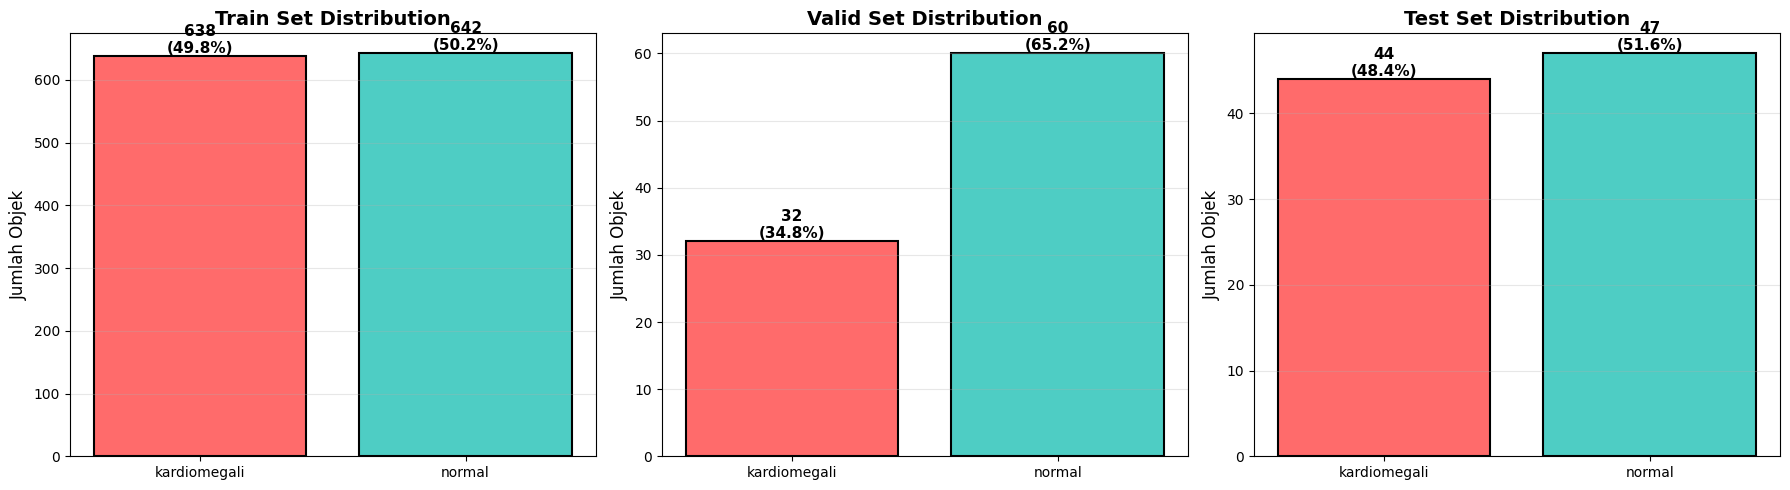

Plot disimpan: /kaggle/working/outputs/class_distribution.png


In [6]:
def get_split_stats(lbl_dir):
    counts = Counter()
    for lbl_file in Path(lbl_dir).glob('*.txt'):
        with open(lbl_file, 'r') as f:
            for line in f.readlines():
                cls_id = int(line.split()[0])
                counts[cls_id] += 1
    return {'class_counts': dict(counts)}

train_stats = get_split_stats(TRAIN_LBL)
valid_stats = get_split_stats(VALID_LBL)
test_stats  = get_split_stats(TEST_LBL)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
splits = [('Train', train_stats), ('Valid', valid_stats), ('Test', test_stats)]
colors_list = [CLASS_COLORS_HEX['kardiomegali'], CLASS_COLORS_HEX['normal']]

for idx, (split_name, stats) in enumerate(splits):
    ax = axes[idx]
    counts = [stats['class_counts'].get(0, 0), stats['class_counts'].get(1, 0)]
    bars = ax.bar(CLASS_NAMES, counts, color=colors_list, edgecolor='black', linewidth=1.5)
    total = sum(counts)
    for bar, count in zip(bars, counts):
        height = bar.get_height()
        percentage = (count / total * 100) if total > 0 else 0
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{count}\n({percentage:.1f}%)',
                ha='center', va='bottom', fontweight='bold', fontsize=11)
    ax.set_title(f'{split_name} Set Distribution', fontsize=14, fontweight='bold')
    ax.set_ylabel('Jumlah Objek', fontsize=12)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'class_distribution.png', dpi=300, bbox_inches='tight')
plt.show()
print(f"Plot disimpan: {OUTPUT_DIR / 'class_distribution.png'}")


## Fungsi Utilitas IoU (Intersection over Union)

Fungsi-fungsi berikut dipakai bersama oleh YOLOv11s dan SSD300-VGG16 untuk:
- Mengonversi label ground truth format YOLO (`cx, cy, w, h` ternormalisasi) menjadi koordinat piksel `x1, y1, x2, y2`.
- Menghitung IoU antara kotak prediksi dan kotak ground truth.
- Mencocokkan (matching) setiap prediksi dengan ground truth yang memiliki IoU tertinggi, untuk keperluan visualisasi dan pelaporan persentase IoU.


In [7]:
def yolo_label_to_xyxy(cx, cy, bw, bh, img_w, img_h):
    """Konversi 1 baris label YOLO (ternormalisasi) -> koordinat piksel [x1,y1,x2,y2]."""
    x1 = (cx - bw / 2) * img_w
    y1 = (cy - bh / 2) * img_h
    x2 = (cx + bw / 2) * img_w
    y2 = (cy + bh / 2) * img_h
    return [x1, y1, x2, y2]

def load_gt_boxes_xyxy(label_path, img_w, img_h):
    """Baca file label YOLO -> list of {'class': int, 'name': str, 'box': [x1,y1,x2,y2]}."""
    boxes = []
    label_path = Path(label_path)
    if not label_path.exists():
        return boxes
    for line in label_path.read_text().strip().splitlines():
        parts = line.strip().split()
        if len(parts) == 5:
            cls = int(parts[0])
            cx, cy, bw, bh = map(float, parts[1:])
            box = yolo_label_to_xyxy(cx, cy, bw, bh, img_w, img_h)
            boxes.append({'class': cls, 'name': CLASS_NAMES[cls], 'box': box})
    return boxes

def compute_iou(boxA, boxB):
    """IoU antara dua kotak format [x1,y1,x2,y2]."""
    xA1, yA1, xA2, yA2 = boxA
    xB1, yB1, xB2, yB2 = boxB

    inter_x1 = max(xA1, xB1)
    inter_y1 = max(yA1, yB1)
    inter_x2 = min(xA2, xB2)
    inter_y2 = min(yA2, yB2)

    inter_w = max(0.0, inter_x2 - inter_x1)
    inter_h = max(0.0, inter_y2 - inter_y1)
    inter_area = inter_w * inter_h

    areaA = max(0.0, xA2 - xA1) * max(0.0, yA2 - yA1)
    areaB = max(0.0, xB2 - xB1) * max(0.0, yB2 - yB1)

    union = areaA + areaB - inter_area
    if union <= 0:
        return 0.0
    return inter_area / union

def match_prediction_to_gt(pred_box, gt_boxes):
    """Cocokkan 1 kotak prediksi dengan GT ber-IoU tertinggi. Return (gt_dict_or_None, iou_value)."""
    best_iou, best_gt = 0.0, None
    for gt in gt_boxes:
        iou = compute_iou(pred_box, gt['box'])
        if iou > best_iou:
            best_iou, best_gt = iou, gt
    return best_gt, best_iou

print('Fungsi utilitas IoU siap digunakan.')


Fungsi utilitas IoU siap digunakan.


## 1. YOLOv11s — Training dengan 3 Konfigurasi Hyperparameter

Setiap konfigurasi dilatih dari checkpoint `yolo11s.pt` (pretrained) secara independen, disimpan pada folder run terpisah agar seluruh hasil (`best.pt`, `results.csv`, kurva training) dapat dibandingkan.


In [8]:
from ultralytics import YOLO

yolo_runs = {}  # config_id -> {'cfg':..., 'best_pt':..., 'run_dir':..., 'results_csv':...}

for cfg in HYPERPARAM_CONFIGS:
    run_name = f"thorax_{cfg['config_id']}"
    print('=' * 80)
    print(f"Training YOLOv11s — {cfg['config_name']} "
          f"(epochs={cfg['epochs']}, batch={cfg['batch']}, patience={cfg['patience']})")
    print('=' * 80)

    yolo_model = YOLO('yolo11s.pt')

    yolo_model.train(
        data=str(DATA_YAML.resolve()),
        epochs=cfg['epochs'],
        imgsz=YOLO_SIZE,
        batch=cfg['batch'],
        device=0 if DEVICE.type == 'cuda' else str(DEVICE),
        workers=4,
        project=str(OUTPUT_DIR / 'yolo11'),
        name=run_name,
        exist_ok=True,

        # early stopping
        patience=cfg['patience'],

        # learning rate
        lr0=0.01,
        lrf=0.01,
        warmup_epochs=3,
        warmup_momentum=0.8,
        warmup_bias_lr=0.1,
        momentum=0.937,
        weight_decay=0.0005,
        optimizer='SGD',

        # augmentasi (identik di semua konfigurasi agar variabel yang diuji murni hyperparameter training)
        degrees=3.0,
        translate=0.05,
        scale=0.10,
        hsv_v=0.20,
        hsv_h=0.0,
        hsv_s=0.0,
        fliplr=0.0,
        flipud=0.0,
        mosaic=0.0,
        mixup=0.0,
        copy_paste=0.0,
        erasing=0.0,
        auto_augment='none',

        verbose=True,
        plots=True,
    )

    run_dir = OUTPUT_DIR / 'yolo11' / run_name
    best_pt = run_dir / 'weights' / 'best.pt'
    results_csv = run_dir / 'results.csv'

    yolo_runs[cfg['config_id']] = {
        'cfg': cfg,
        'run_dir': run_dir,
        'best_pt': best_pt,
        'results_csv': results_csv,
    }

    print(f"\nSelesai {cfg['config_name']} -> best.pt: {best_pt}\n")

print('\nSemua konfigurasi YOLOv11s selesai dilatih.')


Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Training YOLOv11s — Konfigurasi 1 (Baseline) (epochs=25, batch=16, patience=7)
Ultralytics 8.4.115 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=none, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/input/datasets/iicaadsyd/thorax-cardiomegaly-detection/dataset/data.yaml, degrees=3.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=Fa

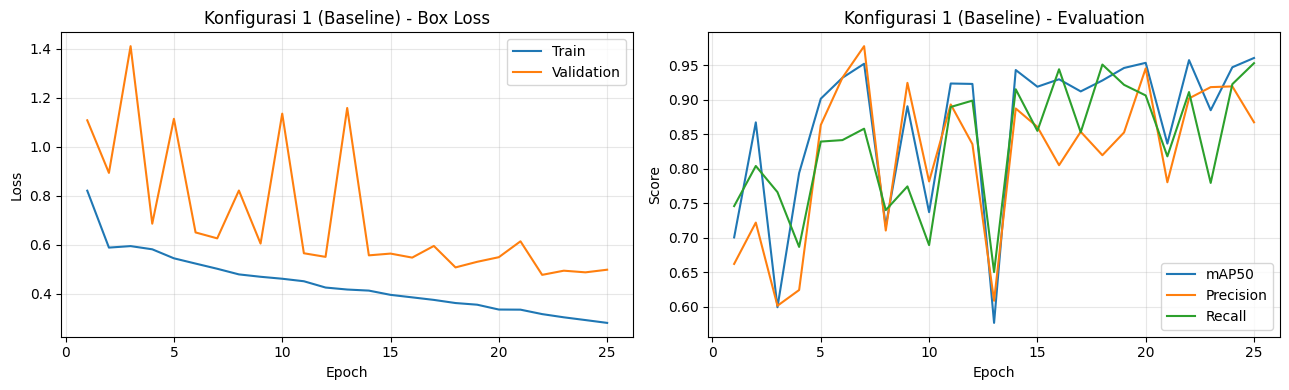

Disimpan : /kaggle/working/outputs/yolo_curve_cfg1.png
Best mAP50 : 0.9605



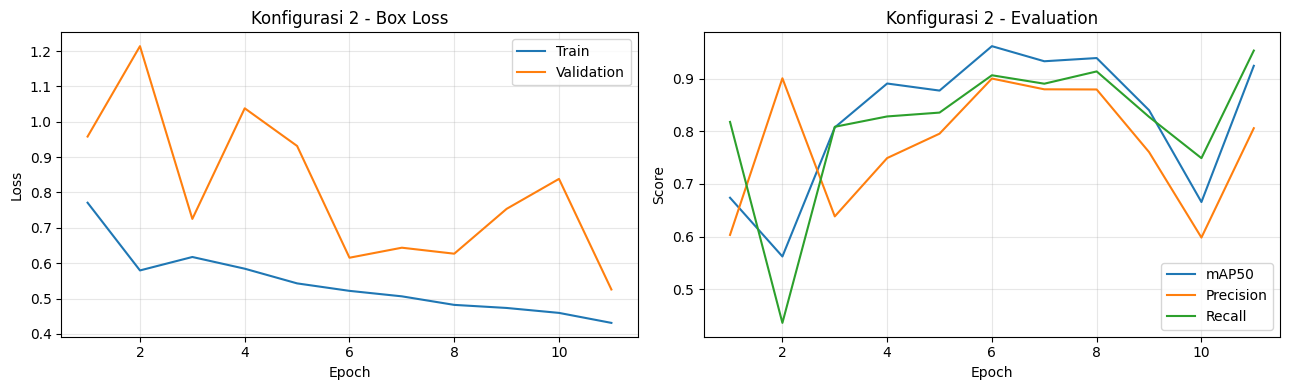

Disimpan : /kaggle/working/outputs/yolo_curve_cfg2.png
Best mAP50 : 0.9615



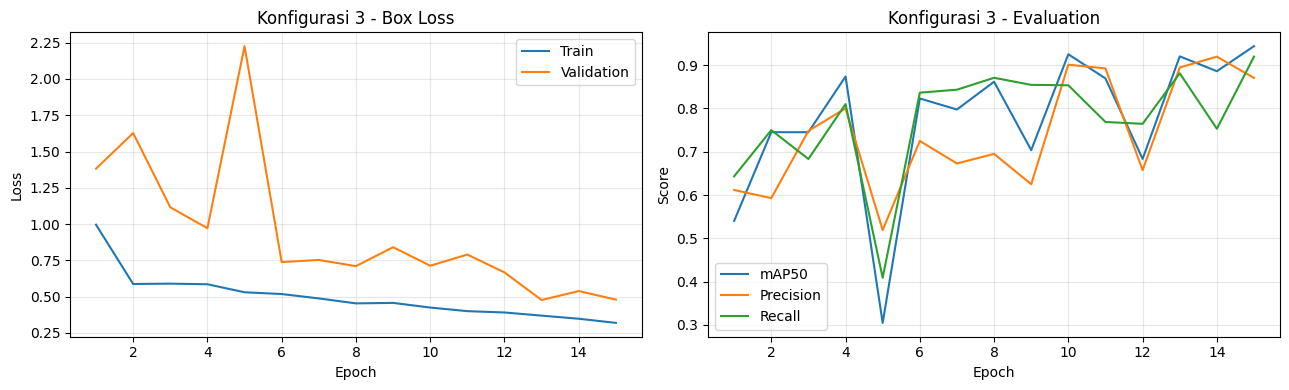

Disimpan : /kaggle/working/outputs/yolo_curve_cfg3.png
Best mAP50 : 0.9439



In [14]:
# ==========================================================
# Visualisasi Training Curve YOLOv11s Setiap Konfigurasi
# ==========================================================

for cfg_id, info in yolo_runs.items():

    results_csv = info['results_csv']

    if not results_csv.exists():
        print(f"{cfg_id} -> results.csv tidak ditemukan.")
        continue

    df = pd.read_csv(results_csv)
    df.columns = df.columns.str.strip()

    fig, ax = plt.subplots(1, 2, figsize=(13,4))

    # -------------------------
    # Loss
    # -------------------------
    ax[0].plot(df['epoch'], df['train/box_loss'], label='Train')
    ax[0].plot(df['epoch'], df['val/box_loss'], label='Validation')

    ax[0].set_title(f"{info['cfg']['config_name']} - Box Loss")
    ax[0].set_xlabel("Epoch")
    ax[0].set_ylabel("Loss")
    ax[0].grid(alpha=0.3)
    ax[0].legend()

    # -------------------------
    # Metric
    # -------------------------
    ax[1].plot(df['epoch'], df['metrics/mAP50(B)'], label='mAP50')
    ax[1].plot(df['epoch'], df['metrics/precision(B)'], label='Precision')
    ax[1].plot(df['epoch'], df['metrics/recall(B)'], label='Recall')

    ax[1].set_title(f"{info['cfg']['config_name']} - Evaluation")
    ax[1].set_xlabel("Epoch")
    ax[1].set_ylabel("Score")
    ax[1].grid(alpha=0.3)
    ax[1].legend()

    plt.tight_layout()

    save_path = OUTPUT_DIR / f"yolo_curve_{cfg_id}.png"
    plt.savefig(save_path, dpi=200, bbox_inches='tight')
    plt.show()

    print(f"Disimpan : {save_path}")
    print(f"Best mAP50 : {df['metrics/mAP50(B)'].max():.4f}\n")

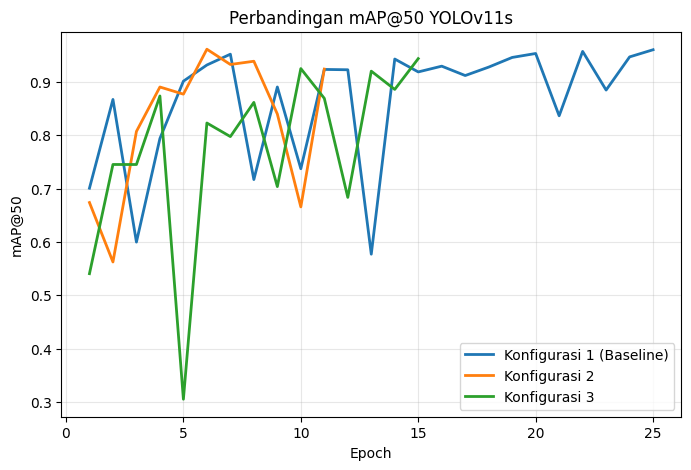

In [15]:
plt.figure(figsize=(8,5))

for cfg_id, info in yolo_runs.items():

    df = pd.read_csv(info['results_csv'])
    df.columns = df.columns.str.strip()

    plt.plot(
        df['epoch'],
        df['metrics/mAP50(B)'],
        linewidth=2,
        label=info['cfg']['config_name']
    )

plt.title("Perbandingan mAP@50 YOLOv11s")
plt.xlabel("Epoch")
plt.ylabel("mAP@50")
plt.grid(alpha=0.3)
plt.legend()

plt.savefig(
    OUTPUT_DIR/"comparison_map50.png",
    dpi=200,
    bbox_inches='tight'
)

plt.show()

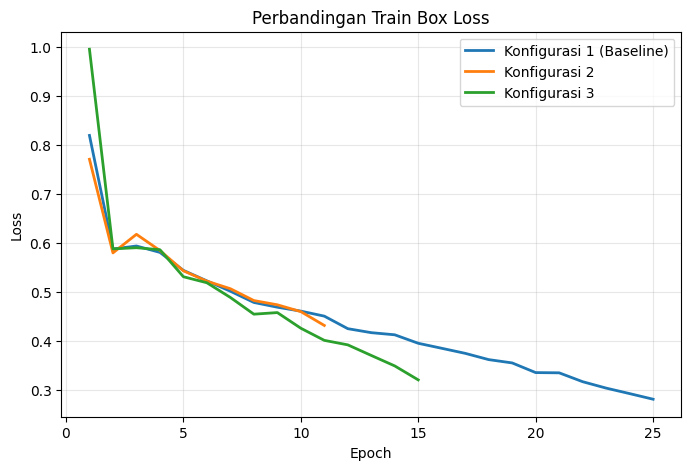

In [16]:
plt.figure(figsize=(8,5))

for cfg_id, info in yolo_runs.items():

    df = pd.read_csv(info['results_csv'])
    df.columns = df.columns.str.strip()

    plt.plot(
        df['epoch'],
        df['train/box_loss'],
        linewidth=2,
        label=info['cfg']['config_name']
    )

plt.title("Perbandingan Train Box Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(alpha=0.3)
plt.legend()

plt.savefig(
    OUTPUT_DIR/"comparison_boxloss.png",
    dpi=200,
    bbox_inches='tight'
)

plt.show()

## 2. YOLOv11s — Evaluasi per Konfigurasi (Validasi & Uji)

Untuk setiap konfigurasi, dievaluasi:
- **Metrik deteksi**: mAP@50, mAP@50-95, Precision, Recall, F1-Score (via `model.val()`), pada split **valid** dan **test**.
- **Confusion matrix**, **classification report**, dan **accuracy** tingkat gambar (1 gambar = 1 objek dominan, sesuai desain dataset), pada split **valid** dan **test**.


In [9]:
def evaluate_yolo_detection_metrics(best_pt, split):
    """Evaluasi metrik deteksi (mAP, precision, recall, F1) YOLOv11s pada split tertentu ('val' atau 'test')."""
    model = YOLO(str(best_pt))
    n_imgs = {'val': len(valid_data), 'test': len(test_data)}[split]

    t0 = time.perf_counter()
    metrics = model.val(
        data=str(DATA_YAML.resolve()),
        split=split,
        device=0 if DEVICE.type == 'cuda' else str(DEVICE),
        verbose=False,
    )
    infer_time = (time.perf_counter() - t0) / max(n_imgs, 1) * 1000  # ms/img

    precision = float(metrics.box.mp)
    recall    = float(metrics.box.mr)
    f1        = 2 * precision * recall / (precision + recall + 1e-8)

    return {
        'mAP@50':     float(metrics.box.map50),
        'mAP@50-95':  float(metrics.box.map),
        'Precision':  precision,
        'Recall':     recall,
        'F1 Score':   f1,
        'Inf (ms)':   infer_time,
    }

print('Fungsi evaluate_yolo_detection_metrics.')


Fungsi evaluate_yolo_detection_metrics.


In [10]:
EXTRA_LABEL = 'Tidak Terdeteksi'
CM_LABELS = CLASS_NAMES + [EXTRA_LABEL]

def evaluate_yolo_classification(best_pt, img_dir, lbl_dir):
    """
    Jalankan prediksi per-gambar dengan YOLOv11s, ambil deteksi dengan confidence tertinggi
    sebagai prediksi kelas gambar, lalu hitung confusion matrix, classification report, accuracy.
    """
    model = YOLO(str(best_pt))
    img_files = sorted([p for p in Path(img_dir).glob('*.*')
                         if p.suffix.lower() in ['.jpg', '.jpeg', '.png']])

    y_true, y_pred, y_scores, detailed = [], [], [], []

    for img_path in tqdm(img_files, desc=f'YOLO predict ({Path(img_dir).parent.name})'):
        label_path = Path(lbl_dir) / f'{img_path.stem}.txt'
        if not label_path.exists():
            continue
        gt_lines = label_path.read_text().strip().splitlines()
        if len(gt_lines) == 0:
            continue
        gt_class = int(gt_lines[0].split()[0])
        y_true.append(CLASS_NAMES[gt_class])

        results = model.predict(source=str(img_path), conf=0.5, iou=0.5,
                                 device=DEVICE, verbose=False)

        if len(results[0].boxes) > 0:
            confs = results[0].boxes.conf.cpu().numpy()
            clss  = results[0].boxes.cls.cpu().numpy().astype(int)
            best_idx = confs.argmax()
            pred_name = CLASS_NAMES[int(clss[best_idx])]
            pred_conf = float(confs[best_idx])
        else:
            pred_name = EXTRA_LABEL
            pred_conf = 0.0

        y_pred.append(pred_name)
        y_scores.append(pred_conf)
        detailed.append({'file': img_path.name, 'true_class': y_true[-1],
                          'pred_class': pred_name, 'confidence': pred_conf,
                          'correct': y_true[-1] == pred_name})

    cm = confusion_matrix(y_true, y_pred, labels=CM_LABELS)
    report = classification_report(y_true, y_pred, labels=CLASS_NAMES,
                                    zero_division=0, output_dict=True)
    report_txt = classification_report(y_true, y_pred, labels=CLASS_NAMES, zero_division=0)
    acc = accuracy_score(y_true, y_pred)

    return {
        'y_true': y_true, 'y_pred': y_pred, 'y_scores': y_scores,
        'confusion_matrix': cm, 'report_dict': report, 'report_txt': report_txt,
        'accuracy': acc, 'detailed': pd.DataFrame(detailed),
    }

print('Fungsi evaluate_yolo_classification siap.')


Fungsi evaluate_yolo_classification siap.


In [11]:
yolo_eval_results = {}  # config_id -> {'valid': {...}, 'test': {...}}

for cfg_id, run_info in yolo_runs.items():
    cfg = run_info['cfg']
    best_pt = run_info['best_pt']
    print('=' * 80)
    print(f"Evaluasi YOLOv11s — {cfg['config_name']}")
    print('=' * 80)

    valid_det = evaluate_yolo_detection_metrics(best_pt, split='val')
    test_det  = evaluate_yolo_detection_metrics(best_pt, split='test')

    valid_cls = evaluate_yolo_classification(best_pt, VALID_IMG, VALID_LBL)
    test_cls  = evaluate_yolo_classification(best_pt, TEST_IMG, TEST_LBL)

    model_size_mb = round(os.path.getsize(best_pt) / (1024 * 1024), 2) if best_pt.exists() else None

    yolo_eval_results[cfg_id] = {
        'cfg': cfg,
        'valid': {**valid_det, 'accuracy': valid_cls['accuracy'],
                   'confusion_matrix': valid_cls['confusion_matrix'],
                   'y_true': valid_cls['y_true'], 'y_pred': valid_cls['y_pred'],
                   'report_txt': valid_cls['report_txt'], 'report_dict': valid_cls['report_dict']},
        'test': {**test_det, 'accuracy': test_cls['accuracy'],
                  'confusion_matrix': test_cls['confusion_matrix'],
                  'y_true': test_cls['y_true'], 'y_pred': test_cls['y_pred'],
                  'report_txt': test_cls['report_txt'], 'report_dict': test_cls['report_dict']},
        'model_size_mb': model_size_mb,
    }

    print(f"\n[Test] mAP@50={test_det['mAP@50']:.4f} | Precision={test_det['Precision']:.4f} | "
          f"Recall={test_det['Recall']:.4f} | F1={test_det['F1 Score']:.4f} | "
          f"Accuracy={test_cls['accuracy']:.4f}")
    print('\nClassification Report (Test):')
    print(test_cls['report_txt'])

# ── Tabel perbandingan 3 konfigurasi YOLOv11s (test set) ────────────────────
yolo_compare_rows = []
for cfg_id, res in yolo_eval_results.items():
    row = {'Konfigurasi': res['cfg']['config_name'],
           'Epoch': res['cfg']['epochs'], 'Batch': res['cfg']['batch'],
           'Patience': res['cfg']['patience']}
    row.update({k: round(v, 4) if isinstance(v, float) else v
                for k, v in res['test'].items()
                if k in ['mAP@50', 'mAP@50-95', 'Precision', 'Recall', 'F1 Score', 'Inf (ms)', 'accuracy']})
    row['Model Size (MB)'] = res['model_size_mb']
    yolo_compare_rows.append(row)

yolo_compare_df = pd.DataFrame(yolo_compare_rows)
yolo_compare_df = yolo_compare_df.rename(columns={'accuracy': 'Accuracy'})
print('\n' + '=' * 90)
print('TABEL PERBANDINGAN 3 KONFIGURASI HYPERPARAMETER — YOLOv11s (Test Set)')
print('=' * 90)
print(yolo_compare_df.to_string(index=False))
yolo_compare_df.to_csv(OUTPUT_DIR / 'yolo11_hyperparam_comparison.csv', index=False)

best_yolo_cfg_id = yolo_compare_df.loc[yolo_compare_df['mAP@50'].idxmax(), 'Konfigurasi']
best_yolo_cfg_id = [k for k, v in yolo_eval_results.items() if v['cfg']['config_name'] == best_yolo_cfg_id][0]
print(f"\nKonfigurasi YOLOv11s terbaik (berdasarkan mAP@50 test): "
      f"{yolo_eval_results[best_yolo_cfg_id]['cfg']['config_name']}")


Evaluasi YOLOv11s — Konfigurasi 1 (Baseline)
Ultralytics 8.4.115 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 101 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.2±0.3 ms, read: 37.2±6.9 MB/s, size: 19.0 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips/
val: Scanning /kaggle/input/datasets/iicaadsyd/thorax-cardiomegaly-detection/dataset/valid/labels... 92 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 92/92 1.1Kit/s 0.1s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/iicaadsyd/thorax-cardiomegaly-detection/dataset/valid is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 3.7it/s 1.6s0.3s
                   all         92         92      0.902      0.914      0.957      0.864
Speed: 2.8ms p

YOLO predict (test): 100%|██████████| 91/91 [00:01<00:00, 64.44it/s]



[Test] mAP@50=0.9096 | Precision=0.8524 | Recall=0.9105 | F1=0.8805 | Accuracy=0.9451

Classification Report (Test):
              precision    recall  f1-score   support

kardiomegali       0.93      0.95      0.94        44
      normal       0.98      0.94      0.96        47

   micro avg       0.96      0.95      0.95        91
   macro avg       0.96      0.95      0.95        91
weighted avg       0.96      0.95      0.95        91

Evaluasi YOLOv11s — Konfigurasi 2
Ultralytics 8.4.115 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 101 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 39.0±5.1 MB/s, size: 18.2 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips/
val: Scanning /kaggle/input/datasets/iicaadsyd/thorax-cardiomegaly-detection/dataset/valid/labels... 92 images, 0 bac

YOLO predict (test): 100%|██████████| 91/91 [00:01<00:00, 72.43it/s]



[Test] mAP@50=0.8768 | Precision=0.8410 | Recall=0.7848 | F1=0.8119 | Accuracy=0.8901

Classification Report (Test):
              precision    recall  f1-score   support

kardiomegali       0.97      0.80      0.88        44
      normal       0.87      0.98      0.92        47

   micro avg       0.91      0.89      0.90        91
   macro avg       0.92      0.89      0.90        91
weighted avg       0.92      0.89      0.90        91

Evaluasi YOLOv11s — Konfigurasi 3
Ultralytics 8.4.115 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 101 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 35.1±5.5 MB/s, size: 18.3 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips/
val: Scanning /kaggle/input/datasets/iicaadsyd/thorax-cardiomegaly-detection/dataset/valid/labels... 92 images, 0 bac

YOLO predict (test): 100%|██████████| 91/91 [00:01<00:00, 70.95it/s]


[Test] mAP@50=0.8233 | Precision=0.7449 | Recall=0.8745 | F1=0.8045 | Accuracy=0.9121

Classification Report (Test):
              precision    recall  f1-score   support

kardiomegali       0.97      0.84      0.90        44
      normal       0.88      0.98      0.93        47

   micro avg       0.92      0.91      0.92        91
   macro avg       0.93      0.91      0.92        91
weighted avg       0.93      0.91      0.92        91


TABEL PERBANDINGAN 3 KONFIGURASI HYPERPARAMETER — YOLOv11s (Test Set)
             Konfigurasi  Epoch  Batch  Patience  mAP@50  mAP@50-95  Precision  Recall  F1 Score  Inf (ms)  Accuracy  Model Size (MB)
Konfigurasi 1 (Baseline)     25     16         7  0.9096     0.8206     0.8524  0.9105    0.8805   55.5213    0.9451            18.27
           Konfigurasi 2     20      8         5  0.8768     0.7533     0.8410  0.7848    0.8119   53.1098    0.8901            18.27
           Konfigurasi 3     15     32        10  0.8233     0.7388     0.7449  0.

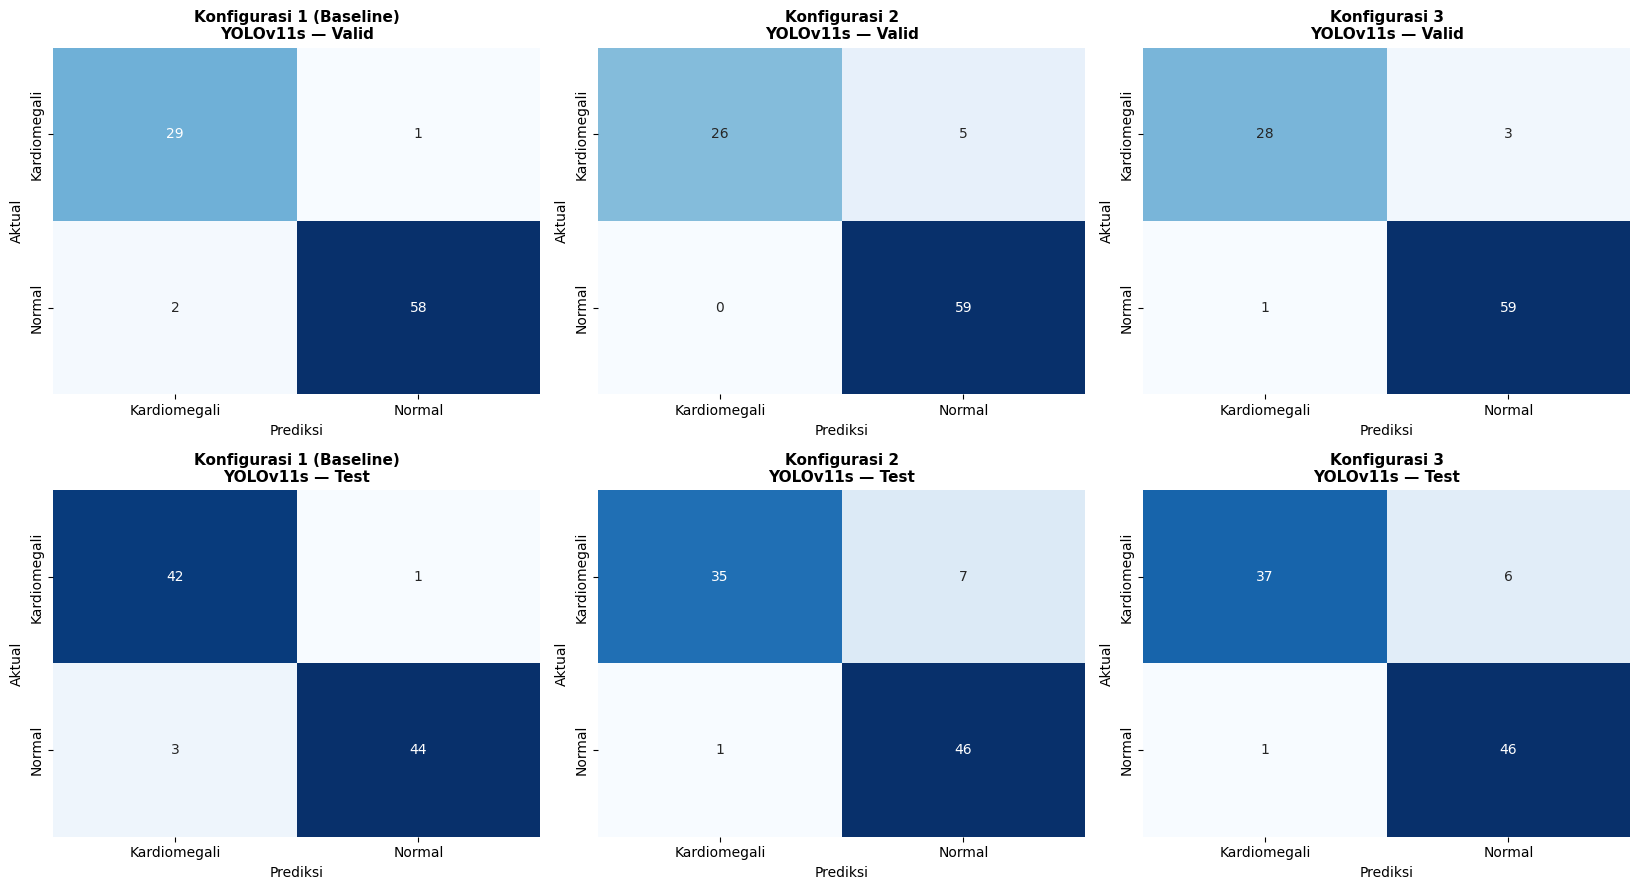

In [12]:
# ── Confusion Matrix (2 Kelas: Kardiomegali vs Normal) untuk setiap konfigurasi ──
# Catatan: prediksi berlabel 'Tidak Terdeteksi' (tanpa deteksi di atas threshold)
# TIDAK disertakan pada matriks ini agar hanya 2 kelas klinis yang tampil.
CLASS_NAMES_DISPLAY = ['Kardiomegali', 'Normal']

fig, axes = plt.subplots(2, len(yolo_eval_results), figsize=(5.5 * len(yolo_eval_results), 9))
if len(yolo_eval_results) == 1:
    axes = axes.reshape(2, 1)

for col, (cfg_id, res) in enumerate(yolo_eval_results.items()):
    for row, split in enumerate(['valid', 'test']):
        ax = axes[row, col]
        y_true = res[split]['y_true']
        y_pred = res[split]['y_pred']
        cm_2class = confusion_matrix(y_true, y_pred, labels=CLASS_NAMES)
        sns.heatmap(cm_2class, annot=True, fmt='d', cmap='Blues', cbar=False,
                    xticklabels=CLASS_NAMES_DISPLAY, yticklabels=CLASS_NAMES_DISPLAY, ax=ax)
        ax.set_title(f"{res['cfg']['config_name']}\nYOLOv11s — {split.capitalize()}",
                     fontsize=11, fontweight='bold')
        ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'yolo11_confusion_matrices.png', dpi=200, bbox_inches='tight')
plt.show()

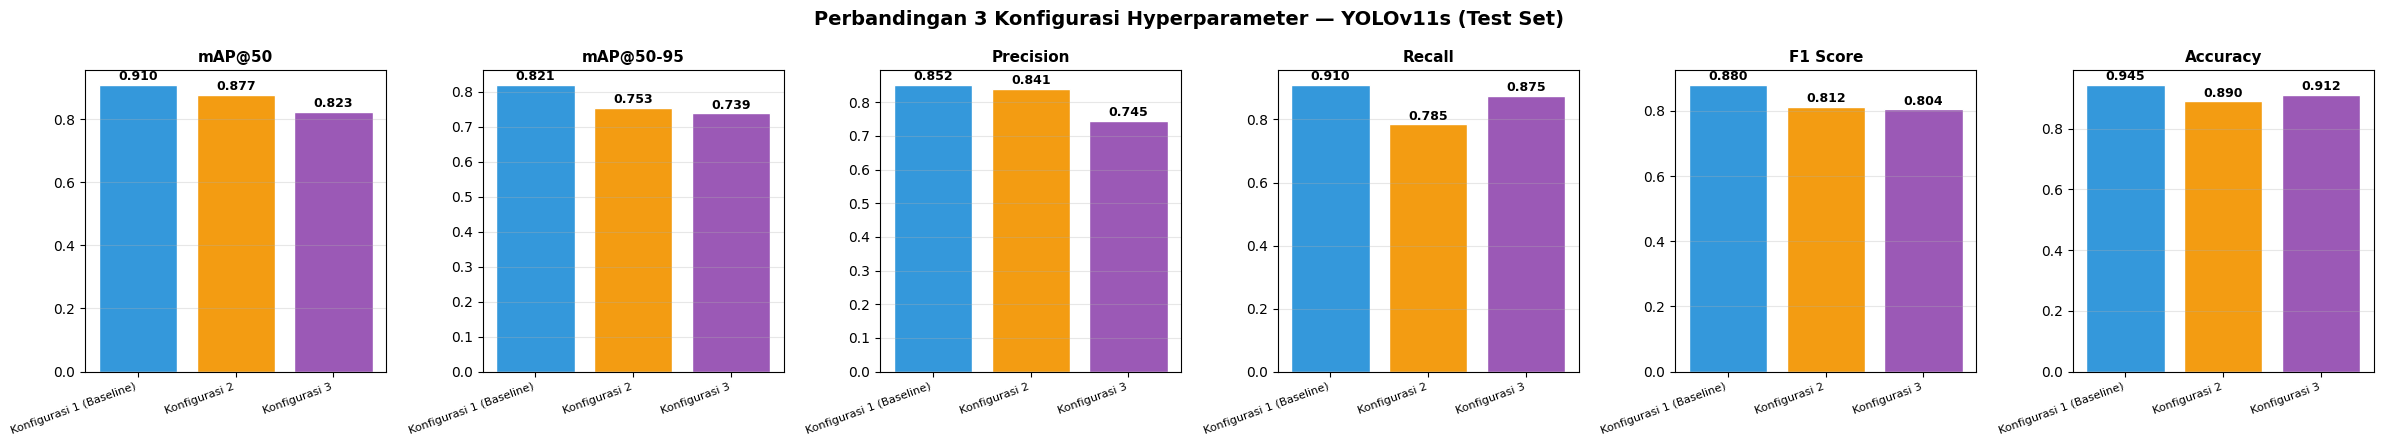

Plot disimpan: /kaggle/working/outputs/yolo11_confusion_matrices.png & yolo11_hyperparam_barchart.png


In [13]:
# ── Bar chart perbandingan metrik antar konfigurasi ──────────────────────────
metric_cols = ['mAP@50', 'mAP@50-95', 'Precision', 'Recall', 'F1 Score', 'Accuracy']
fig, axes = plt.subplots(1, len(metric_cols), figsize=(24, 4.5))
fig.suptitle('Perbandingan 3 Konfigurasi Hyperparameter — YOLOv11s (Test Set)',
             fontsize=14, fontweight='bold')

configs_lbl = yolo_compare_df['Konfigurasi'].tolist()
bar_colors = ['#3498DB', '#F39C12', '#9B59B6']

for ax, col in zip(axes, metric_cols):
    vals = yolo_compare_df[col].tolist()
    bars = ax.bar(configs_lbl, vals, color=bar_colors[:len(configs_lbl)], edgecolor='white')
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.005,
                f'{val:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
    ax.set_title(col, fontsize=11, fontweight='bold')
    ax.set_xticklabels(configs_lbl, rotation=20, ha='right', fontsize=8)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'yolo11_hyperparam_barchart.png', dpi=200, bbox_inches='tight')
plt.show()
print(f"Plot disimpan: {OUTPUT_DIR / 'yolo11_confusion_matrices.png'} & yolo11_hyperparam_barchart.png")

## 3. SSD300-VGG16 — Dataset & Model


In [17]:
import albumentations as A
from albumentations.pytorch import ToTensorV2

class ThoraxDatasetSSD(Dataset):
    def __init__(self, img_dir, lbl_dir, img_size=300, augment=False):
        self.img_dir  = Path(img_dir)
        self.lbl_dir  = Path(lbl_dir)
        self.img_size = img_size
        self.augment  = augment
        self.img_files = sorted(
            list(self.img_dir.glob('*.jpg')) +
            list(self.img_dir.glob('*.jpeg')) +
            list(self.img_dir.glob('*.png'))
        )
        self.aug_transform  = self._build_aug()
        self.base_transform = self._build_base()

    def _build_aug(self):
        return A.Compose([
            A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.10, rotate_limit=5,
                                border_mode=cv2.BORDER_CONSTANT, value=0, p=0.6),
            A.RandomBrightnessContrast(brightness_limit=0.20, contrast_limit=0.20, p=0.5),
            A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=0.4),
            A.GaussNoise(var_limit=(5.0, 20.0), p=0.3),
        ], bbox_params=A.BboxParams(format='pascal_voc', label_fields=['class_labels'],
                                     min_visibility=0.3, clip=True))

    def _build_base(self):
        return A.Compose([
            A.Resize(self.img_size, self.img_size),
            A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
            ToTensorV2()
        ], bbox_params=A.BboxParams(format='pascal_voc', label_fields=['class_labels'],
                                     min_visibility=0.3, clip=True))

    def __len__(self):
        return len(self.img_files)

    def __getitem__(self, idx):
        img_path = self.img_files[idx]
        lbl_path = self.lbl_dir / f'{img_path.stem}.txt'

        img = np.array(Image.open(img_path).convert('RGB'))
        h, w = img.shape[:2]

        bboxes, labels = [], []
        if lbl_path.exists():
            for line in lbl_path.read_text().strip().splitlines():
                parts = line.strip().split()
                if len(parts) == 5:
                    cls = int(parts[0])
                    cx, cy, bw, bh = map(float, parts[1:])
                    x1, y1, x2, y2 = yolo_label_to_xyxy(cx, cy, bw, bh, w, h)
                    x1, y1 = max(0, x1), max(0, y1)
                    x2, y2 = min(w, x2), min(h, y2)
                    if x2 > x1 and y2 > y1:
                        bboxes.append([x1, y1, x2, y2])
                        labels.append(cls + 1)  # +1 karena 0 = background pada SSD

        if self.augment and len(bboxes) > 0:
            transformed = self.aug_transform(image=img, bboxes=bboxes, class_labels=labels)
            img, bboxes, labels = transformed['image'], transformed['bboxes'], transformed['class_labels']

        transformed = self.base_transform(image=img, bboxes=bboxes, class_labels=labels)
        img_t = transformed['image']
        bboxes = transformed['bboxes']
        labels = transformed['class_labels']

        if len(bboxes) == 0:
            boxes_t = torch.zeros((0, 4), dtype=torch.float32)
            labels_t = torch.zeros((0,), dtype=torch.int64)
        else:
            boxes_t = torch.as_tensor(bboxes, dtype=torch.float32)
            labels_t = torch.as_tensor(labels, dtype=torch.int64)

        target = {'boxes': boxes_t, 'labels': labels_t}
        return img_t, target

def collate_fn_ssd(batch):
    return tuple(zip(*batch))

print('ThoraxDatasetSSD siap.')


ThoraxDatasetSSD siap.


In [18]:
def build_ssd_model(num_classes=NUM_CLASSES_SSD, score_thresh=0.01, nms_thresh=0.45):
    model = ssd300_vgg16(
        weights=SSD300_VGG16_Weights.DEFAULT,
        score_thresh=score_thresh,
        nms_thresh=nms_thresh,
        detections_per_img=10,
    )
    in_channels = [512, 1024, 512, 256, 256, 256]
    num_anchors = model.anchor_generator.num_anchors_per_location()
    model.head.classification_head = SSDClassificationHead(
        in_channels=in_channels, num_anchors=num_anchors, num_classes=num_classes)
    return model

def freeze_backbone(model, freeze_up_to=10):
    for i, (name, param) in enumerate(model.backbone.named_parameters()):
        if i < freeze_up_to:
            param.requires_grad = False

def unfreeze_backbone(model):
    for param in model.backbone.parameters():
        param.requires_grad = True

print('build_ssd_model & helper freeze/unfreeze siap.')


build_ssd_model & helper freeze/unfreeze siap.


## 4. SSD300-VGG16 — Training dengan 3 Konfigurasi Hyperparameter

Setiap konfigurasi membangun ulang model SSD300-VGG16 dari bobot pretrained (backbone VGG16 sebagian di-freeze pada awal training), lalu dilatih dengan `epochs`, `batch`, dan `patience` (early stopping) sesuai konfigurasi. Input size SSD tetap 300×300 di ketiga konfigurasi.


In [19]:
def train_one_epoch_ssd(model, loader, optimizer, device, accum_steps=2):
    model.train()
    total_loss = 0.0
    optimizer.zero_grad()
    pbar = tqdm(loader, desc='  Train', leave=False)
    for step, (imgs, targets) in enumerate(pbar):
        imgs = [img.to(device) for img in imgs]
        targets = [{'boxes': t['boxes'].to(device), 'labels': t['labels'].to(device)} for t in targets]
        loss_dict = model(imgs, targets)
        loss = sum(loss_dict.values()) / accum_steps
        loss.backward()
        if (step + 1) % accum_steps == 0 or (step + 1) == len(loader):
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            optimizer.zero_grad()
        total_loss += loss.item() * accum_steps
        pbar.set_postfix({'loss': f'{loss.item() * accum_steps:.4f}'})
    return total_loss / max(len(loader), 1)

@torch.no_grad()
def eval_loss_ssd(model, loader, device):
    """SSD (torchvision) hanya mengembalikan loss dict saat model.train() — dipakai murni untuk
    memantau val loss (early stopping), tanpa update gradien (dibungkus no_grad)."""
    model.train()
    total_loss = 0.0
    for imgs, targets in tqdm(loader, desc='  Val', leave=False):
        imgs = [img.to(device) for img in imgs]
        targets = [{'boxes': t['boxes'].to(device), 'labels': t['labels'].to(device)} for t in targets]
        loss_dict = model(imgs, targets)
        loss = sum(loss_dict.values())
        total_loss += loss.item()
    return total_loss / max(len(loader), 1)

print('Fungsi training/eval-loss SSD siap.')


Fungsi training/eval-loss SSD siap.


In [20]:
def train_ssd_config(cfg):
    """Latih SSD300-VGG16 dari awal (pretrained backbone) untuk 1 konfigurasi hyperparameter."""
    train_ds = ThoraxDatasetSSD(TRAIN_IMG, TRAIN_LBL, img_size=SSD_SIZE, augment=True)
    valid_ds = ThoraxDatasetSSD(VALID_IMG, VALID_LBL, img_size=SSD_SIZE, augment=False)

    train_loader = DataLoader(train_ds, batch_size=cfg['batch'], shuffle=True,
                               num_workers=2, collate_fn=collate_fn_ssd)
    valid_loader = DataLoader(valid_ds, batch_size=cfg['batch'], shuffle=False,
                               num_workers=2, collate_fn=collate_fn_ssd)

    model = build_ssd_model().to(DEVICE)
    freeze_backbone(model, freeze_up_to=10)

    SSD_WARMUP_EPOCHS = 3
    SSD_LR, SSD_LR_WARMUP = 5e-3, 5e-4
    SSD_MOMENTUM, SSD_WEIGHT_DECAY = 0.9, 5e-4
    ACCUM_STEPS = max(1, 16 // cfg['batch'])  # jaga effective batch ~16

    optimizer = optim.SGD(filter(lambda p: p.requires_grad, model.parameters()),
                           lr=SSD_LR_WARMUP, momentum=SSD_MOMENTUM,
                           weight_decay=SSD_WEIGHT_DECAY, nesterov=True)

    ckpt_path = OUTPUT_DIR / f"ssd_best_{cfg['config_id']}.pt"
    train_losses, val_losses = [], []
    best_val_loss, no_improve = float('inf'), 0
    scheduler_started = False

    for epoch in range(1, cfg['epochs'] + 1):
        if epoch == SSD_WARMUP_EPOCHS + 1 and not scheduler_started:
            unfreeze_backbone(model)
            for g in optimizer.param_groups:
                g['lr'] = SSD_LR
            scheduler_started = True

        print(f"  Epoch {epoch}/{cfg['epochs']}")
        tr_loss = train_one_epoch_ssd(model, train_loader, optimizer, DEVICE, accum_steps=ACCUM_STEPS)
        va_loss = eval_loss_ssd(model, valid_loader, DEVICE)
        train_losses.append(tr_loss)
        val_losses.append(va_loss)
        print(f'    train_loss={tr_loss:.4f} | val_loss={va_loss:.4f}')

        if va_loss < best_val_loss:
            best_val_loss = va_loss
            no_improve = 0
            torch.save(model.state_dict(), ckpt_path)
        else:
            no_improve += 1
            if no_improve >= cfg['patience']:
                print(f"    Early stopping pada epoch {epoch} (patience={cfg['patience']})")
                break

    return {'ckpt_path': ckpt_path, 'train_losses': train_losses,
            'val_losses': val_losses, 'best_val_loss': best_val_loss}


ssd_runs = {}
for cfg in HYPERPARAM_CONFIGS:
    print('=' * 80)
    print(f"Training SSD300-VGG16 — {cfg['config_name']} "
          f"(epochs={cfg['epochs']}, batch={cfg['batch']}, patience={cfg['patience']})")
    print('=' * 80)
    run_info = train_ssd_config(cfg)
    ssd_runs[cfg['config_id']] = {'cfg': cfg, **run_info}
    print(f"\nSelesai {cfg['config_name']} -> checkpoint: {run_info['ckpt_path']}\n")

print('\nSemua konfigurasi SSD300-VGG16 selesai dilatih.')


Training SSD300-VGG16 — Konfigurasi 1 (Baseline) (epochs=25, batch=16, patience=7)
Downloading: "https://download.pytorch.org/models/ssd300_vgg16_coco-b556d3b4.pth" to /root/.cache/torch/hub/checkpoints/ssd300_vgg16_coco-b556d3b4.pth


100%|██████████| 136M/136M [00:00<00:00, 162MB/s]  


  Epoch 1/25


    train_loss=6.6009 | val_loss=3.2515
  Epoch 2/25


    train_loss=2.7972 | val_loss=2.1298
  Epoch 3/25


    train_loss=2.1775 | val_loss=1.7217
  Epoch 4/25


... (51 outputs left out)

    train_loss=0.7053 | val_loss=0.8385
  Epoch 13/15


    train_loss=0.7029 | val_loss=0.7483
  Epoch 14/15


    train_loss=0.6388 | val_loss=0.7281
  Epoch 15/15


    train_loss=0.6119 | val_loss=0.9780

Selesai Konfigurasi 3 -> checkpoint: /kaggle/working/outputs/ssd_best_cfg3.pt


Semua konfigurasi SSD300-VGG16 selesai dilatih.


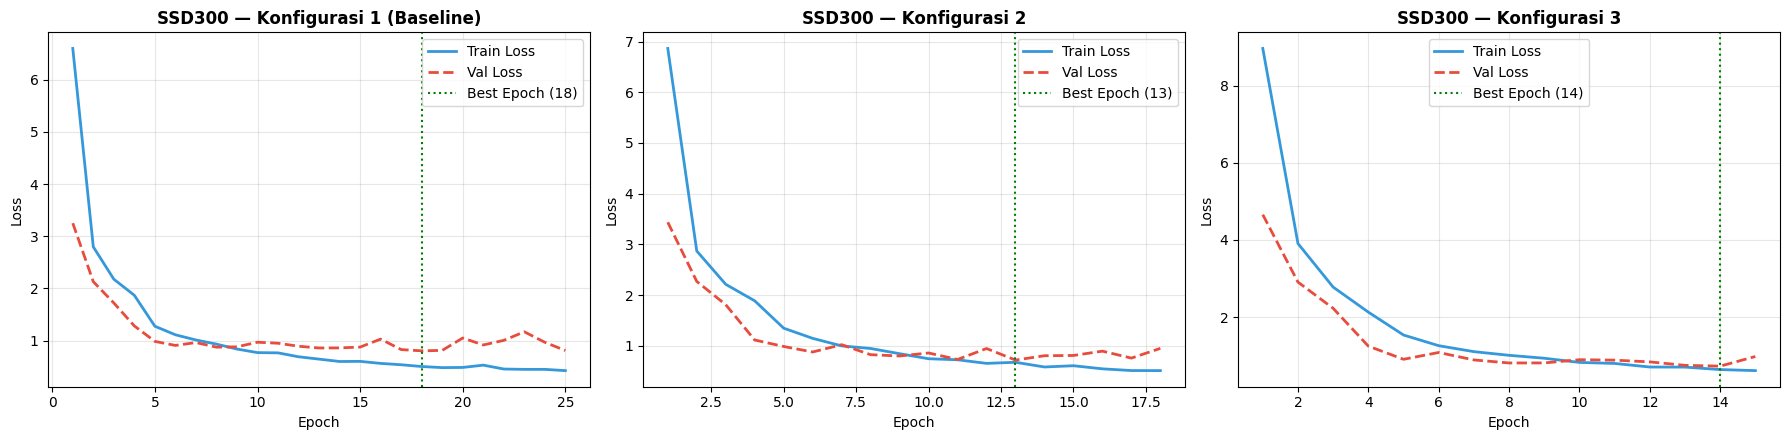

Plot disimpan: /kaggle/working/outputs/ssd_training_curves_all_configs.png


In [23]:
fig, axes = plt.subplots(1, len(ssd_runs), figsize=(6 * len(ssd_runs), 4.5))
if len(ssd_runs) == 1:
    axes = [axes]

for ax, (cfg_id, run) in zip(axes, ssd_runs.items()):
    epochs_r = range(1, len(run['train_losses']) + 1)
    ax.plot(epochs_r, run['train_losses'], label='Train Loss', color='#3498DB', linewidth=2)
    ax.plot(epochs_r, run['val_losses'], label='Val Loss', color='#E74C3C', linewidth=2, linestyle='--')
    best_ep = int(np.argmin(run['val_losses'])) + 1
    ax.axvline(x=best_ep, color='green', linestyle=':', linewidth=1.5, label=f'Best Epoch ({best_ep})')
    ax.set_title(f"SSD300 — {run['cfg']['config_name']}", fontsize=12, fontweight='bold')
    ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
    ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'ssd_training_curves_all_configs.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Plot disimpan: {OUTPUT_DIR / 'ssd_training_curves_all_configs.png'}")


## 5. SSD300-VGG16 — Evaluasi per Konfigurasi (Validasi & Uji)


In [24]:
from torchmetrics.detection.mean_ap import MeanAveragePrecision

def evaluate_ssd_detection_metrics(ckpt_path, img_dir, lbl_dir, batch_size=16, conf_thresh=0.5):
    model = build_ssd_model().to(DEVICE)
    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE, weights_only=True))
    model.eval()

    ds = ThoraxDatasetSSD(img_dir, lbl_dir, img_size=SSD_SIZE, augment=False)
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False,
                         num_workers=2, collate_fn=collate_fn_ssd)

    metric_map = MeanAveragePrecision(iou_type='bbox', class_metrics=True)
    all_preds_pr, all_targets_pr = [], []

    t0 = time.perf_counter()
    with torch.no_grad():
        for imgs, targets in tqdm(loader, desc='SSD Eval', leave=False):
            imgs = [img.to(DEVICE) for img in imgs]
            preds = model(imgs)

            preds_cpu = [{'boxes': p['boxes'].cpu(), 'scores': p['scores'].cpu(),
                          'labels': p['labels'].cpu()} for p in preds]
            targets_cpu = [{'boxes': t['boxes'].cpu(), 'labels': t['labels'].cpu()} for t in targets]
            metric_map.update(preds_cpu, targets_cpu)

            for pred, tgt in zip(preds, targets):
                keep = pred['scores'] >= conf_thresh
                all_preds_pr.append({'boxes': pred['boxes'][keep].cpu(),
                                      'scores': pred['scores'][keep].cpu(),
                                      'labels': pred['labels'][keep].cpu()})
                all_targets_pr.append({'boxes': tgt['boxes'].cpu(), 'labels': tgt['labels'].cpu()})

    infer_time = (time.perf_counter() - t0) / max(len(ds), 1) * 1000  # ms/img
    res = metric_map.compute()

    map50 = float(res['map_50'])
    map50_95 = float(res['map'])

    # precision/recall/F1 manual berbasis matching sederhana per gambar (1 objek per gambar)
    tp = fp = fn = 0
    for pred, tgt in zip(all_preds_pr, all_targets_pr):
        gt_labels = tgt['labels'].tolist()
        pred_labels = pred['labels'].tolist()
        if len(gt_labels) == 0:
            fp += len(pred_labels)
            continue
        if len(pred_labels) == 0:
            fn += len(gt_labels)
            continue
        best_idx = int(pred['scores'].argmax())
        if pred_labels[best_idx] == gt_labels[0]:
            tp += 1
        else:
            fp += 1
            fn += 1

    precision = tp / (tp + fp + 1e-8)
    recall = tp / (tp + fn + 1e-8)
    f1 = 2 * precision * recall / (precision + recall + 1e-8)

    return {'mAP@50': map50, 'mAP@50-95': map50_95, 'Precision': precision,
            'Recall': recall, 'F1 Score': f1, 'Inf (ms)': infer_time}

print('Fungsi evaluate_ssd_detection_metrics siap.')


Fungsi evaluate_ssd_detection_metrics siap.


In [25]:
def evaluate_ssd_classification(ckpt_path, img_dir, lbl_dir, conf_thresh=0.5, batch_size=16):
    model = build_ssd_model().to(DEVICE)
    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE, weights_only=True))
    model.eval()

    ds = ThoraxDatasetSSD(img_dir, lbl_dir, img_size=SSD_SIZE, augment=False)
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False,
                         num_workers=2, collate_fn=collate_fn_ssd)

    y_true, y_pred, y_scores, detailed = [], [], [], []

    with torch.no_grad():
        for imgs, targets in tqdm(loader, desc=f'SSD predict ({Path(img_dir).parent.name})', leave=False):
            imgs = [img.to(DEVICE) for img in imgs]
            preds = model(imgs)
            for pred, target in zip(preds, targets):
                if len(target['labels']) == 0:
                    continue
                gt_cls_idx = int(target['labels'][0].item()) - 1  # kembalikan ke 0-based
                y_true.append(CLASS_NAMES[gt_cls_idx])

                keep = pred['scores'] >= conf_thresh
                scores = pred['scores'][keep]
                labels = pred['labels'][keep]

                if len(scores) > 0:
                    best_idx = int(scores.argmax())
                    pred_cls_idx = int(labels[best_idx].item()) - 1
                    pred_name = CLASS_NAMES[pred_cls_idx]
                    pred_conf = float(scores[best_idx].item())
                else:
                    pred_name = EXTRA_LABEL
                    pred_conf = 0.0

                y_pred.append(pred_name)
                y_scores.append(pred_conf)
                detailed.append({'true_class': y_true[-1], 'pred_class': pred_name,
                                  'confidence': pred_conf, 'correct': y_true[-1] == pred_name})

    cm = confusion_matrix(y_true, y_pred, labels=CM_LABELS)
    report = classification_report(y_true, y_pred, labels=CLASS_NAMES, zero_division=0, output_dict=True)
    report_txt = classification_report(y_true, y_pred, labels=CLASS_NAMES, zero_division=0)
    acc = accuracy_score(y_true, y_pred)

    return {'y_true': y_true, 'y_pred': y_pred, 'y_scores': y_scores,
            'confusion_matrix': cm, 'report_dict': report, 'report_txt': report_txt,
            'accuracy': acc, 'detailed': pd.DataFrame(detailed)}

print('Fungsi evaluate_ssd_classification siap.')


Fungsi evaluate_ssd_classification siap.


In [26]:
ssd_eval_results = {}

for cfg_id, run_info in ssd_runs.items():
    cfg = run_info['cfg']
    ckpt_path = run_info['ckpt_path']
    print('=' * 80)
    print(f"Evaluasi SSD300-VGG16 — {cfg['config_name']}")
    print('=' * 80)

    valid_det = evaluate_ssd_detection_metrics(ckpt_path, VALID_IMG, VALID_LBL, batch_size=cfg['batch'])
    test_det  = evaluate_ssd_detection_metrics(ckpt_path, TEST_IMG, TEST_LBL, batch_size=cfg['batch'])

    valid_cls = evaluate_ssd_classification(ckpt_path, VALID_IMG, VALID_LBL, batch_size=cfg['batch'])
    test_cls  = evaluate_ssd_classification(ckpt_path, TEST_IMG, TEST_LBL, batch_size=cfg['batch'])

    model_size_mb = round(os.path.getsize(ckpt_path) / (1024 * 1024), 2) if Path(ckpt_path).exists() else None

    ssd_eval_results[cfg_id] = {
        'cfg': cfg,
        'valid': {**valid_det, 'accuracy': valid_cls['accuracy'],
                  'confusion_matrix': valid_cls['confusion_matrix'],
                  'y_true': valid_cls['y_true'], 'y_pred': valid_cls['y_pred'],
                  'report_txt': valid_cls['report_txt'], 'report_dict': valid_cls['report_dict']},
        'test': {**test_det, 'accuracy': test_cls['accuracy'],
                 'confusion_matrix': test_cls['confusion_matrix'],
                 'y_true': test_cls['y_true'], 'y_pred': test_cls['y_pred'],
                 'report_txt': test_cls['report_txt'], 'report_dict': test_cls['report_dict']},
        'model_size_mb': model_size_mb,
    }

    print(f"\n[Test] mAP@50={test_det['mAP@50']:.4f} | Precision={test_det['Precision']:.4f} | "
          f"Recall={test_det['Recall']:.4f} | F1={test_det['F1 Score']:.4f} | "
          f"Accuracy={test_cls['accuracy']:.4f}")
    print('\nClassification Report (Test):')
    print(test_cls['report_txt'])

# ── Tabel perbandingan 3 konfigurasi SSD300-VGG16 (test set) ────────────────
ssd_compare_rows = []
for cfg_id, res in ssd_eval_results.items():
    row = {'Konfigurasi': res['cfg']['config_name'],
           'Epoch': res['cfg']['epochs'], 'Batch': res['cfg']['batch'],
           'Patience': res['cfg']['patience']}
    row.update({k: round(v, 4) if isinstance(v, float) else v
                for k, v in res['test'].items()
                if k in ['mAP@50', 'mAP@50-95', 'Precision', 'Recall', 'F1 Score', 'Inf (ms)', 'accuracy']})
    row['Model Size (MB)'] = res['model_size_mb']
    ssd_compare_rows.append(row)

ssd_compare_df = pd.DataFrame(ssd_compare_rows)
ssd_compare_df = ssd_compare_df.rename(columns={'accuracy': 'Accuracy'})
print('\n' + '=' * 90)
print('TABEL PERBANDINGAN 3 KONFIGURASI HYPERPARAMETER — SSD300-VGG16 (Test Set)')
print('=' * 90)
print(ssd_compare_df.to_string(index=False))
ssd_compare_df.to_csv(OUTPUT_DIR / 'ssd300_hyperparam_comparison.csv', index=False)

best_ssd_cfg_name = ssd_compare_df.loc[ssd_compare_df['mAP@50'].idxmax(), 'Konfigurasi']
best_ssd_cfg_id = [k for k, v in ssd_eval_results.items() if v['cfg']['config_name'] == best_ssd_cfg_name][0]
print(f"\nKonfigurasi SSD300-VGG16 terbaik (berdasarkan mAP@50 test): "
      f"{ssd_eval_results[best_ssd_cfg_id]['cfg']['config_name']}")


Evaluasi SSD300-VGG16 — Konfigurasi 1 (Baseline)



[Test] mAP@50=0.9041 | Precision=0.9231 | Recall=0.9231 | F1=0.9231 | Accuracy=0.9231

Classification Report (Test):
              precision    recall  f1-score   support

kardiomegali       0.95      0.89      0.92        44
      normal       0.90      0.96      0.93        47

    accuracy                           0.92        91
   macro avg       0.93      0.92      0.92        91
weighted avg       0.92      0.92      0.92        91

Evaluasi SSD300-VGG16 — Konfigurasi 2



[Test] mAP@50=0.9203 | Precision=0.9231 | Recall=0.9231 | F1=0.9231 | Accuracy=0.9231

Classification Report (Test):
              precision    recall  f1-score   support

kardiomegali       0.97      0.86      0.92        44
      normal       0.88      0.98      0.93        47

    accuracy                           0.92        91
   macro avg       0.93      0.92      0.92        91
weighted avg       0.93      0.92      0.92        91

Evaluasi SSD300-VGG16 — Konfigurasi 3



[Test] mAP@50=0.9084 | Precision=0.9551 | Recall=0.9341 | F1=0.9444 | Accuracy=0.9341

Classification Report (Test):
              precision    recall  f1-score   support

kardiomegali       0.95      0.91      0.93        44
      normal       0.96      0.96      0.96        47

   micro avg       0.96      0.93      0.94        91
   macro avg       0.95      0.93      0.94        91
weighted avg       0.95      0.93      0.94        91


TABEL PERBANDINGAN 3 KONFIGURASI HYPERPARAMETER — SSD300-VGG16 (Test Set)
             Konfigurasi  Epoch  Batch  Patience  mAP@50  mAP@50-95  Precision  Recall  F1 Score  Inf (ms)  Accuracy  Model Size (MB)
Konfigurasi 1 (Baseline)     25     16         7  0.9041     0.7555     0.9231  0.9231    0.9231   21.1120    0.9231            91.12
           Konfigurasi 2     20      8         5  0.9203     0.7783     0.9231  0.9231    0.9231   22.4579    0.9231            91.12
           Konfigurasi 3     15     32        10  0.9084     0.7509     0.9551

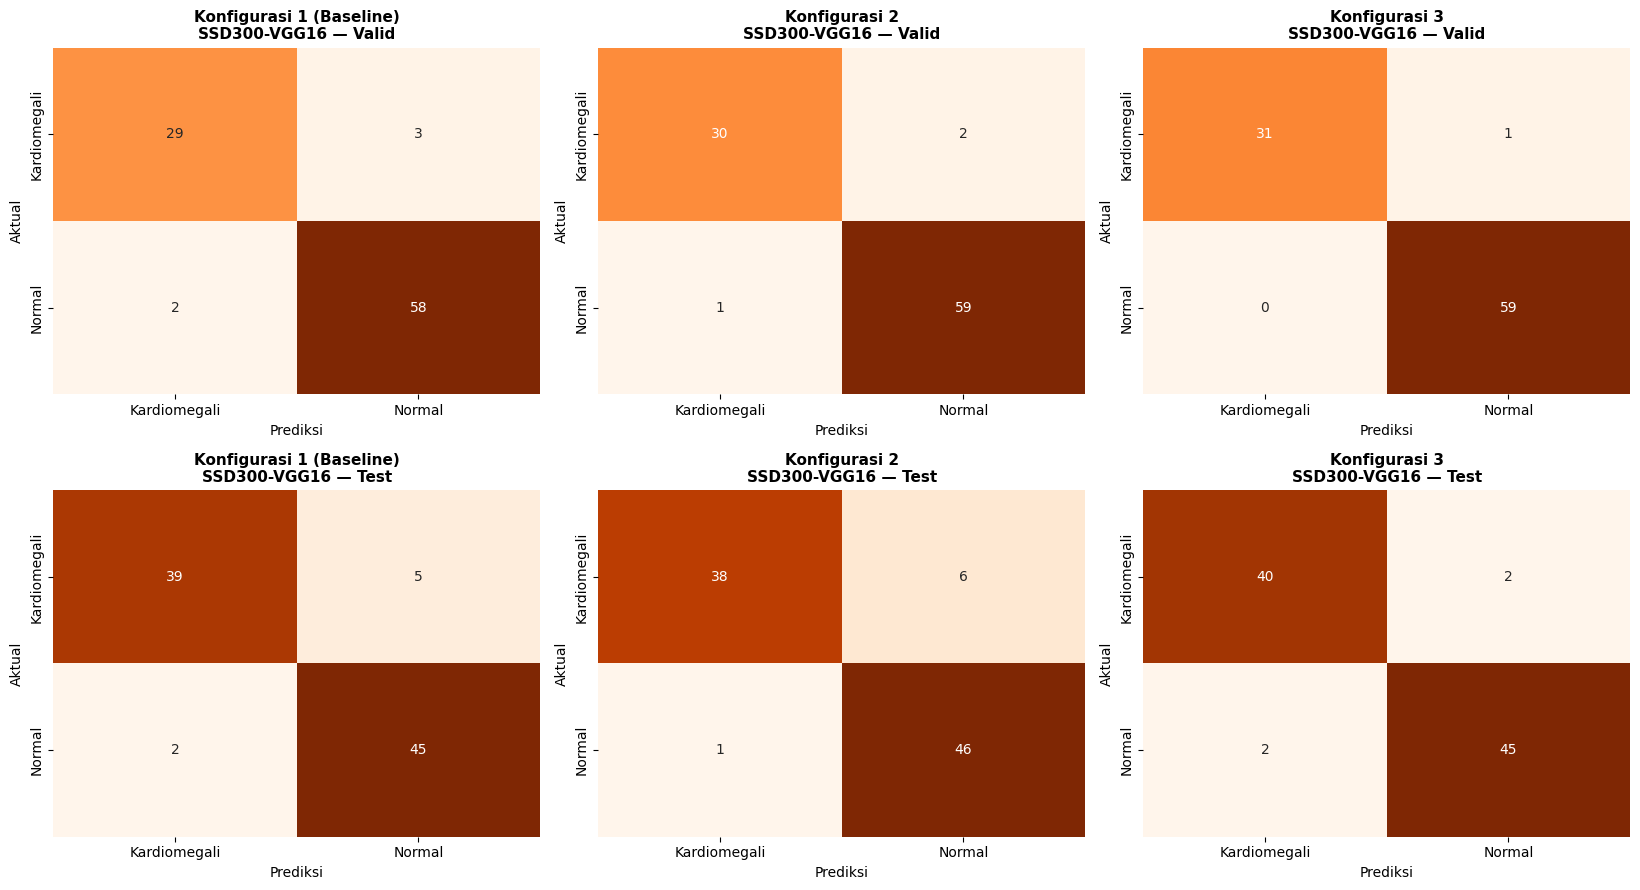

In [37]:
# ── Confusion Matrix (2 Kelas: Kardiomegali vs Normal) untuk setiap konfigurasi SSD ──
# Catatan: prediksi berlabel 'Tidak Terdeteksi' TIDAK disertakan agar hanya 2 kelas klinis yang tampil.
fig, axes = plt.subplots(2, len(ssd_eval_results), figsize=(5.5 * len(ssd_eval_results), 9))
if len(ssd_eval_results) == 1:
    axes = axes.reshape(2, 1)

for col, (cfg_id, res) in enumerate(ssd_eval_results.items()):
    for row, split in enumerate(['valid', 'test']):
        ax = axes[row, col]
        y_true = res[split]['y_true']
        y_pred = res[split]['y_pred']
        cm_2class = confusion_matrix(y_true, y_pred, labels=CLASS_NAMES)
        sns.heatmap(cm_2class, annot=True, fmt='d', cmap='Oranges', cbar=False,
                    xticklabels=CLASS_NAMES_DISPLAY, yticklabels=CLASS_NAMES_DISPLAY, ax=ax)
        ax.set_title(f"{res['cfg']['config_name']}\nSSD300-VGG16 — {split.capitalize()}",
                     fontsize=11, fontweight='bold')
        ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'ssd300_confusion_matrices.png', dpi=200, bbox_inches='tight')
plt.show()

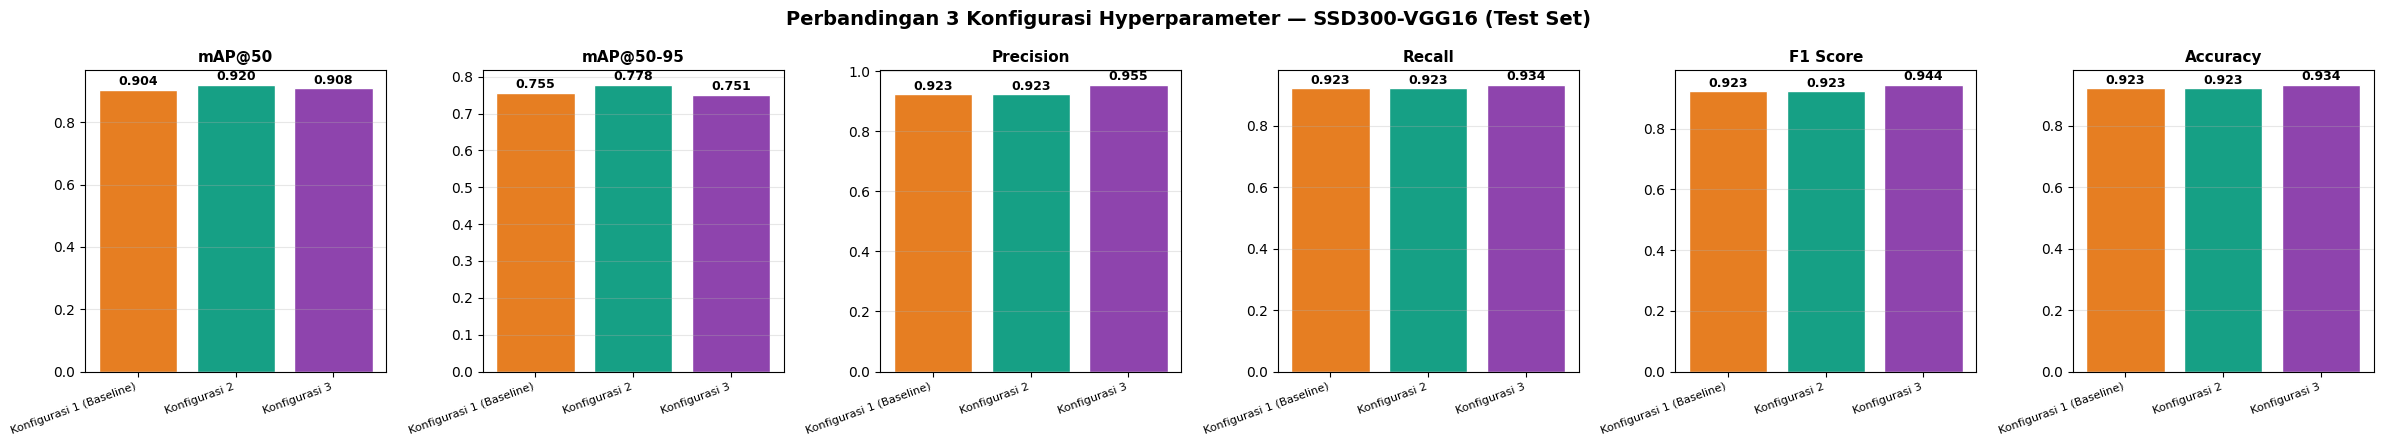

Plot disimpan: /kaggle/working/outputs/ssd300_confusion_matrices.png & ssd300_hyperparam_barchart.png


In [38]:
# ── Bar chart perbandingan metrik antar konfigurasi ──────────────────────────
metric_cols = ['mAP@50', 'mAP@50-95', 'Precision', 'Recall', 'F1 Score', 'Accuracy']
fig, axes = plt.subplots(1, len(metric_cols), figsize=(24, 4.5))
fig.suptitle('Perbandingan 3 Konfigurasi Hyperparameter — SSD300-VGG16 (Test Set)',
             fontsize=14, fontweight='bold')

configs_lbl = ssd_compare_df['Konfigurasi'].tolist()
bar_colors = ['#E67E22', '#16A085', '#8E44AD']

for ax, col in zip(axes, metric_cols):
    vals = ssd_compare_df[col].tolist()
    bars = ax.bar(configs_lbl, vals, color=bar_colors[:len(configs_lbl)], edgecolor='white')
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.005,
                f'{val:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
    ax.set_title(col, fontsize=11, fontweight='bold')
    ax.set_xticklabels(configs_lbl, rotation=20, ha='right', fontsize=8)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'ssd300_hyperparam_barchart.png', dpi=200, bbox_inches='tight')
plt.show()
print(f"Plot disimpan: {OUTPUT_DIR / 'ssd300_confusion_matrices.png'} & ssd300_hyperparam_barchart.png")

## 6. Perbandingan Akhir: Konfigurasi Terbaik YOLOv11s vs SSD300-VGG16

Konfigurasi terbaik masing-masing algoritma (berdasarkan mAP@50 tertinggi pada test set) dibandingkan secara head-to-head, termasuk accuracy, ukuran model, dan waktu inferensi.


In [33]:
best_yolo = yolo_eval_results[best_yolo_cfg_id]
best_ssd  = ssd_eval_results[best_ssd_cfg_id]

BEST_YOLO_PT   = yolo_runs[best_yolo_cfg_id]['best_pt']
BEST_SSD_CKPT  = ssd_runs[best_ssd_cfg_id]['ckpt_path']

final_comparison = pd.DataFrame({
    'Metrik': ['Konfigurasi Terpilih', 'mAP@50', 'mAP@50-95', 'Precision', 'Recall',
               'F1-Score', 'Accuracy', 'Inference Time (ms/img)', 'Ukuran Model (MB)'],
    'YOLOv11s': [
        best_yolo['cfg']['config_name'],
        round(best_yolo['test']['mAP@50'], 4),
        round(best_yolo['test']['mAP@50-95'], 4),
        round(best_yolo['test']['Precision'], 4),
        round(best_yolo['test']['Recall'], 4),
        round(best_yolo['test']['F1 Score'], 4),
        round(best_yolo['test']['accuracy'], 4),
        round(best_yolo['test']['Inf (ms)'], 2),
        best_yolo['model_size_mb'],
    ],
    'SSD300-VGG16': [
        best_ssd['cfg']['config_name'],
        round(best_ssd['test']['mAP@50'], 4),
        round(best_ssd['test']['mAP@50-95'], 4),
        round(best_ssd['test']['Precision'], 4),
        round(best_ssd['test']['Recall'], 4),
        round(best_ssd['test']['F1 Score'], 4),
        round(best_ssd['test']['accuracy'], 4),
        round(best_ssd['test']['Inf (ms)'], 2),
        best_ssd['model_size_mb'],
    ],
})

print('=' * 80)
print('TABEL PERBANDINGAN AKHIR — KONFIGURASI TERBAIK MASING-MASING ALGORITMA')
print('=' * 80)
print(final_comparison.to_string(index=False))
final_comparison.to_csv(OUTPUT_DIR / 'final_best_config_comparison.csv', index=False)

TABEL PERBANDINGAN AKHIR — KONFIGURASI TERBAIK MASING-MASING ALGORITMA
                 Metrik                 YOLOv11s  SSD300-VGG16
   Konfigurasi Terpilih Konfigurasi 1 (Baseline) Konfigurasi 2
                 mAP@50                   0.9096        0.9203
              mAP@50-95                   0.8206        0.7783
              Precision                   0.8524        0.9231
                 Recall                   0.9105        0.9231
               F1-Score                   0.8805        0.9231
               Accuracy                   0.9451        0.9231
Inference Time (ms/img)                    55.52         22.46
      Ukuran Model (MB)                    18.27         91.12


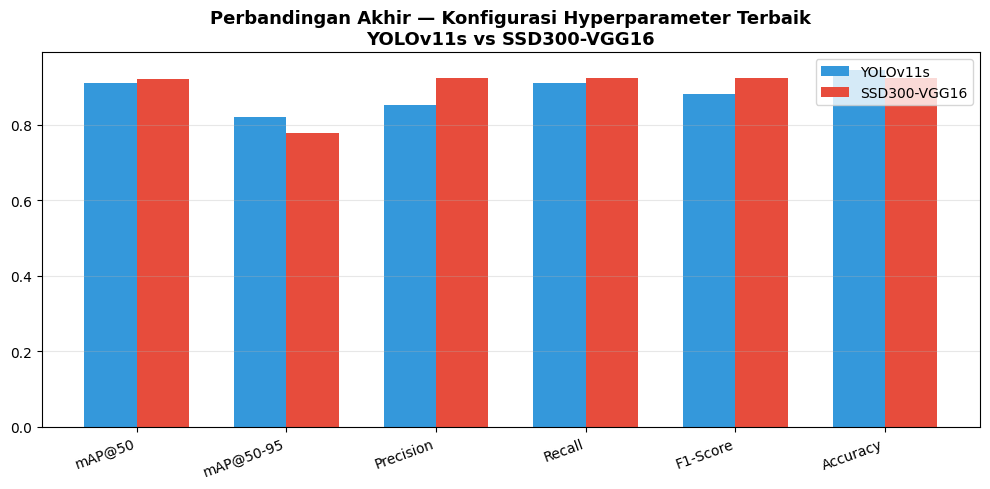


Best YOLOv11s checkpoint : /kaggle/working/outputs/yolo11/thorax_cfg1/weights/best.pt
Best SSD300 checkpoint   : /kaggle/working/outputs/ssd_best_cfg2.pt


In [36]:
# ── Bar chart perbandingan akhir ─────────────────────────────────────────────
metric_rows = final_comparison.iloc[1:7]  # mAP50 .. accuracy
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(metric_rows))
width = 0.35
ax.bar(x - width/2, metric_rows['YOLOv11s'].astype(float), width, label='YOLOv11s', color='#3498DB')
ax.bar(x + width/2, metric_rows['SSD300-VGG16'].astype(float), width, label='SSD300-VGG16', color='#E74C3C')
ax.set_xticks(x)
ax.set_xticklabels(metric_rows['Metrik'], rotation=20, ha='right')
ax.set_title('Perbandingan Akhir — Konfigurasi Hyperparameter Terbaik\nYOLOv11s vs SSD300-VGG16',
             fontsize=13, fontweight='bold')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'final_comparison_barchart.png', dpi=200, bbox_inches='tight')
plt.show()

print(f"\nBest YOLOv11s checkpoint : {BEST_YOLO_PT}")
print(f"Best SSD300 checkpoint   : {BEST_SSD_CKPT}")


## Kurva Training YOLOv11s — Konfigurasi Terbaik

Kurva *loss* dan metrik evaluasi (mAP@50, precision, recall) per epoch diambil dari `results.csv` milik konfigurasi YOLOv11s terbaik (`BEST_YOLO_PT`).

## 7. Visualisasi Lokasi IoU pada Prediksi Citra X-Ray Thoraks

Ketentuan visualisasi (sesuai revisi penguji):

- Kotak **ground truth (anotasi dokter)** → warna **merah**.
- Kotak **prediksi kelas kardiomegali** → warna `#FF6B6B`.
- Kotak **prediksi kelas normal** → warna `#4ECDC4`.
- Setiap kotak prediksi diberi label: **nama kelas**, **confidence score**, dan **persentase IoU** terhadap ground truth yang paling bertumpang tindih.

Visualisasi dijalankan pada model dengan **konfigurasi hyperparameter terbaik** untuk masing-masing algoritma.


In [39]:
def get_yolo_predictions(model, image_path, conf=0.25, iou_nms=0.5):
    """Return list of {'class_idx','name','box':[x1,y1,x2,y2],'conf'} pada koordinat gambar asli."""
    results = model.predict(source=str(image_path), conf=conf, iou=iou_nms,
                             device=DEVICE, verbose=False)
    preds = []
    for box in results[0].boxes:
        cls_idx = int(box.cls[0].item())
        conf_score = float(box.conf[0].item())
        x1, y1, x2, y2 = box.xyxy[0].cpu().numpy().tolist()
        preds.append({'class_idx': cls_idx, 'name': CLASS_NAMES[cls_idx],
                      'box': [x1, y1, x2, y2], 'conf': conf_score})
    return preds

_ssd_transform = T.Compose([
    T.Resize((SSD_SIZE, SSD_SIZE)),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

def get_ssd_predictions(model, image_path, conf_thresh=0.25):
    """Return list of {'class_idx','name','box':[x1,y1,x2,y2],'conf'} pada koordinat gambar asli."""
    pil_img = Image.open(image_path).convert('RGB')
    w, h = pil_img.size
    img_tensor = _ssd_transform(pil_img).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        prediction = model(img_tensor)[0]

    keep = prediction['scores'] >= conf_thresh
    boxes  = prediction['boxes'][keep].cpu().numpy()
    scores = prediction['scores'][keep].cpu().numpy()
    labels = prediction['labels'][keep].cpu().numpy()

    preds = []
    for box, score, label in zip(boxes, scores, labels):
        cls_idx = int(label) - 1  # kembalikan ke 0-based
        if cls_idx < 0 or cls_idx >= len(CLASS_NAMES):
            continue
        x1, y1, x2, y2 = box
        x1 = x1 * w / SSD_SIZE; x2 = x2 * w / SSD_SIZE
        y1 = y1 * h / SSD_SIZE; y2 = y2 * h / SSD_SIZE
        preds.append({'class_idx': cls_idx, 'name': CLASS_NAMES[cls_idx],
                      'box': [x1, y1, x2, y2], 'conf': float(score)})
    return preds

print('Fungsi get_yolo_predictions & get_ssd_predictions siap.')


Fungsi get_yolo_predictions & get_ssd_predictions siap.


In [40]:
def draw_iou_visualization(image_path, label_path, pred_boxes, model_name, ax=None):
    """
    Gambar 1 citra dengan:
      - kotak ground truth (merah)
      - kotak prediksi (warna sesuai kelas), dilabeli nama kelas, confidence, dan %IoU
    """
    img = cv2.imread(str(image_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    gt_boxes = load_gt_boxes_xyxy(label_path, w, h)

    # Gambar ground truth (merah)
    for gt in gt_boxes:
        x1, y1, x2, y2 = [int(v) for v in gt['box']]
        cv2.rectangle(img, (x1, y1), (x2, y2), GT_COLOR_RGB, 3)
        gt_label = f"GT: {gt['name']}"
        (tw, th), _ = cv2.getTextSize(gt_label, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 2)
        cv2.rectangle(img, (x1, max(0, y1 - th - 12)), (x1 + tw + 10, y1), GT_COLOR_RGB, -1)
        cv2.putText(img, gt_label, (x1 + 5, max(12, y1 - 6)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2, cv2.LINE_AA)

    # Gambar prediksi (warna per kelas) + label kelas, confidence, IoU%
    for pred in pred_boxes:
        x1, y1, x2, y2 = [int(v) for v in pred['box']]
        color = CLASS_COLORS_RGB[pred['name']]
        matched_gt, iou_val = match_prediction_to_gt(pred['box'], gt_boxes)

        cv2.rectangle(img, (x1, y1), (x2, y2), color, 3)
        label_text = f"{pred['name']} | conf={pred['conf']:.2f} | IoU={iou_val*100:.1f}%"
        (tw, th), _ = cv2.getTextSize(label_text, cv2.FONT_HERSHEY_SIMPLEX, 0.55, 2)
        label_y2 = y2 + th + 14 if (y2 + th + 20) < h else y1
        label_y1 = label_y2 - th - 12
        cv2.rectangle(img, (x1, max(0, label_y1)), (x1 + tw + 10, label_y2), color, -1)
        cv2.putText(img, label_text, (x1 + 5, label_y2 - 6),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 2, cv2.LINE_AA)

    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 7))
        standalone = True
    else:
        standalone = False

    ax.imshow(img)
    ax.set_title(f'{model_name}\n{Path(image_path).name}', fontsize=10, fontweight='bold')
    ax.axis('off')

    if standalone:
        plt.tight_layout()
        return fig
    return ax

print('Fungsi draw_iou_visualization siap.')
print("Legenda warna -> GT (merah): anotasi dokter | "
      f"kardiomegali: {CLASS_COLORS_HEX['kardiomegali']} | normal: {CLASS_COLORS_HEX['normal']}")


Fungsi draw_iou_visualization siap.
Legenda warna -> GT (merah): anotasi dokter | kardiomegali: #FF6B6B | normal: #4ECDC4


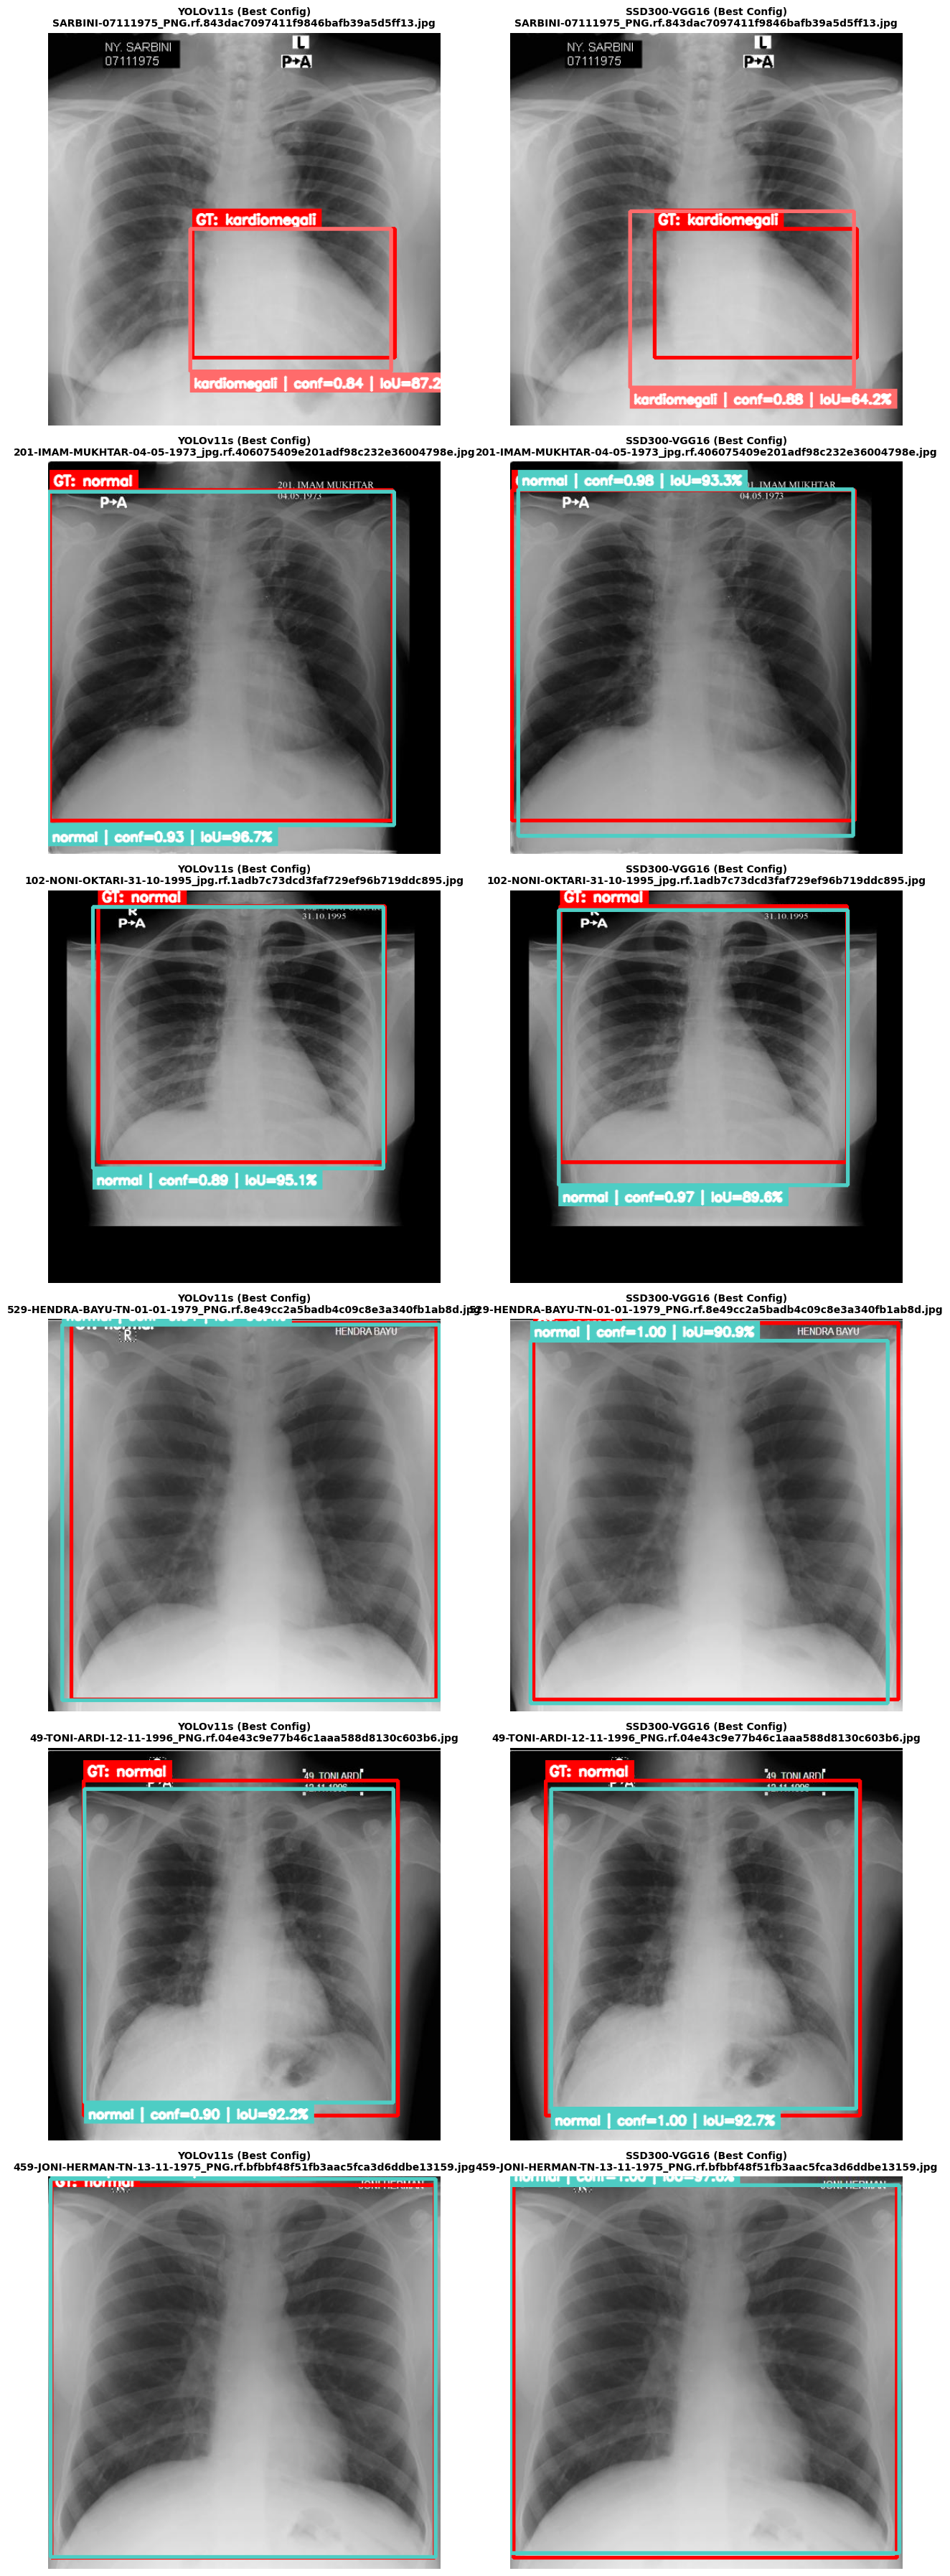


Ringkasan Prediksi & IoU per Objek:
                                                                     file        model   pred_class  confidence matched_gt_class  iou_percent
             SARBINI-07111975_PNG.rf.843dac7097411f9846bafb39a5d5ff13.jpg     YOLOv11s kardiomegali      0.8438     kardiomegali    87.150000
             SARBINI-07111975_PNG.rf.843dac7097411f9846bafb39a5d5ff13.jpg SSD300-VGG16 kardiomegali      0.8770     kardiomegali    64.190002
  201-IMAM-MUKHTAR-04-05-1973_jpg.rf.406075409e201adf98c232e36004798e.jpg     YOLOv11s       normal      0.9286           normal    96.710000
  201-IMAM-MUKHTAR-04-05-1973_jpg.rf.406075409e201adf98c232e36004798e.jpg SSD300-VGG16       normal      0.9817           normal    93.290001
   102-NONI-OKTARI-31-10-1995_jpg.rf.1adb7c73dcd3faf729ef96b719ddc895.jpg     YOLOv11s       normal      0.8884           normal    95.100000
   102-NONI-OKTARI-31-10-1995_jpg.rf.1adb7c73dcd3faf729ef96b719ddc895.jpg SSD300-VGG16       normal      0.9690

In [41]:
N_SAMPLES = 6  # jumlah citra uji yang divisualisasikan

test_image_files = sorted([p for p in TEST_IMG.glob('*.*')
                            if p.suffix.lower() in ['.jpg', '.jpeg', '.png']])
random.seed(SEED)
sample_images = random.sample(test_image_files, min(N_SAMPLES, len(test_image_files)))

# Load model terbaik
best_yolo_model = YOLO(str(BEST_YOLO_PT))

best_ssd_model = build_ssd_model().to(DEVICE)
best_ssd_model.load_state_dict(torch.load(BEST_SSD_CKPT, map_location=DEVICE, weights_only=True))
best_ssd_model.eval()

CONF_VIS = 0.25  # threshold confidence untuk visualisasi (agar deteksi lemah tetap terlihat)

iou_summary_rows = []

fig, axes = plt.subplots(len(sample_images), 2, figsize=(14, 6 * len(sample_images)))
if len(sample_images) == 1:
    axes = axes.reshape(1, 2)

for row_idx, img_path in enumerate(sample_images):
    lbl_path = TEST_LBL / f'{img_path.stem}.txt'

    yolo_preds = get_yolo_predictions(best_yolo_model, img_path, conf=CONF_VIS)
    ssd_preds  = get_ssd_predictions(best_ssd_model, img_path, conf_thresh=CONF_VIS)

    draw_iou_visualization(img_path, lbl_path, yolo_preds, 'YOLOv11s (Best Config)', ax=axes[row_idx, 0])
    draw_iou_visualization(img_path, lbl_path, ssd_preds, 'SSD300-VGG16 (Best Config)', ax=axes[row_idx, 1])

    img_pil = Image.open(img_path)
    w, h = img_pil.size
    gt_boxes = load_gt_boxes_xyxy(lbl_path, w, h)

    for model_name, preds in [('YOLOv11s', yolo_preds), ('SSD300-VGG16', ssd_preds)]:
        for pred in preds:
            matched_gt, iou_val = match_prediction_to_gt(pred['box'], gt_boxes)
            iou_summary_rows.append({
                'file': img_path.name, 'model': model_name,
                'pred_class': pred['name'], 'confidence': round(pred['conf'], 4),
                'matched_gt_class': matched_gt['name'] if matched_gt else None,
                'iou_percent': round(iou_val * 100, 2),
            })

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'iou_visualization_samples.png', dpi=150, bbox_inches='tight')
plt.show()

iou_summary_df = pd.DataFrame(iou_summary_rows)
print('\nRingkasan Prediksi & IoU per Objek:')
print(iou_summary_df.to_string(index=False))
iou_summary_df.to_csv(OUTPUT_DIR / 'iou_visualization_summary.csv', index=False)
print(f"\nGambar disimpan: {OUTPUT_DIR / 'iou_visualization_samples.png'}")
print(f"Tabel disimpan : {OUTPUT_DIR / 'iou_visualization_summary.csv'}")


## 8. Fungsi Inferensi untuk Citra Baru (YOLOv11s & SSD300-VGG16)

Bagian ini menyediakan fungsi siap pakai untuk menjalankan inferensi pada citra X-ray baru (di luar dataset), baik dengan model **YOLOv11s** maupun **SSD300-VGG16**, mengikuti gaya visualisasi (bounding box + label kelas + confidence) yang biasa dipakai secara lokal.

Gunakan `load_ssd_for_inference()` sekali untuk memuat model SSD terbaik ke memori, lalu panggil `predict_ssd(...)`, `predict_yolo(...)`, atau `predict_compare(...)` untuk citra apa pun.

In [45]:
# ==========================================================
# FUNGSI INFERENSI — YOLOv11s & SSD300-VGG16 (untuk citra baru)
# ==========================================================
import cv2
import torch
import matplotlib.pyplot as plt
import torchvision.transforms as T
from PIL import Image
from pathlib import Path

CONF_THRESHOLD_DEFAULT = 0.50

# Transform SSD (harus identik dengan saat training/eval)
_ssd_infer_transform = T.Compose([
    T.Resize((SSD_SIZE, SSD_SIZE)),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])


def load_ssd_for_inference(ckpt_path=None):
    """
    Muat checkpoint SSD300-VGG16 untuk inferensi.
    Default: model terbaik hasil training (BEST_SSD_CKPT).
    """
    ckpt_path = Path(ckpt_path) if ckpt_path else Path(BEST_SSD_CKPT)
    model = build_ssd_model().to(DEVICE)
    model.load_state_dict(
        torch.load(ckpt_path, map_location=DEVICE, weights_only=True)
    )
    model.eval()
    return model


def predict_ssd(image_path, model=None, conf_threshold=CONF_THRESHOLD_DEFAULT, show=True, ax=None):
    """
    Jalankan inferensi SSD300-VGG16 pada 1 citra dan gambar bounding box hasil deteksi
    (mengikuti gaya visualisasi lokal: kotak warna per kelas + label + confidence).

    Return: (detections, orig_img_rgb_with_boxes)
    """
    image_path = Path(image_path)
    if model is None:
        model = load_ssd_for_inference()

    # ── Load citra ──
    orig_img = cv2.imread(str(image_path))
    orig_img = cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB)
    h, w = orig_img.shape[:2]

    pil_img = Image.open(image_path).convert('RGB')
    img_tensor = _ssd_infer_transform(pil_img).unsqueeze(0).to(DEVICE)

    # ── Predict ──
    with torch.no_grad():
        prediction = model(img_tensor)[0]

    # ── Filter confidence ──
    keep = prediction['scores'] >= conf_threshold
    boxes  = prediction['boxes'][keep].cpu().numpy()
    scores = prediction['scores'][keep].cpu().numpy()
    labels = prediction['labels'][keep].cpu().numpy()

    detections = []
    for box, score, label in zip(boxes, scores, labels):
        cls = int(label) - 1  # 0 = background pada SSD -> kembalikan ke 0-based
        if cls < 0 or cls >= len(CLASS_NAMES):
            continue

        # ── Scale ke ukuran citra asli ──
        x1, y1, x2, y2 = box
        x1 = int(max(0, x1 * w / SSD_SIZE))
        y1 = int(max(0, y1 * h / SSD_SIZE))
        x2 = int(min(w, x2 * w / SSD_SIZE))
        y2 = int(min(h, y2 * h / SSD_SIZE))

        color = CLASS_COLORS_RGB[CLASS_NAMES[cls]]

        # ── Draw bounding box ──
        cv2.rectangle(orig_img, (x1, y1), (x2, y2), color, 3)

        # ── Label teks ──
        text = f'{CLASS_NAMES[cls]}: {score:.2f}'
        (text_w, text_h), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, 0.7, 2)

        # Fix posisi label supaya tidak keluar dari citra
        if y1 - text_h - 10 < 0:
            label_y1, label_y2 = y1, y1 + text_h + 10
            text_x, text_y = x1, y1 + text_h + 5
        else:
            label_y1, label_y2 = y1 - text_h - 10, y1
            text_x, text_y = x1, y1 - 5

        cv2.rectangle(orig_img, (x1, label_y1), (x1 + text_w + 10, label_y2), color, -1)
        cv2.putText(orig_img, text, (text_x + 5, text_y),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)

        detections.append({
            'class': CLASS_NAMES[cls],
            'confidence': float(score),
            'box': [x1, y1, x2, y2],
        })

    if show:
        standalone = ax is None
        if standalone:
            fig, ax = plt.subplots(figsize=(10, 10))
        ax.imshow(orig_img)
        ax.axis('off')
        ax.set_title(f'SSD300 Prediction: {image_path.name}', fontsize=14, fontweight='bold')
        if standalone:
            plt.show()

    return detections, orig_img


def predict_yolo(image_path, model=None, conf_threshold=CONF_THRESHOLD_DEFAULT, show=True, ax=None):
    """
    Jalankan inferensi YOLOv11s pada 1 citra dan gambar bounding box hasil deteksi
    (memakai fungsi plot bawaan Ultralytics: results[0].plot()).

    Return: (detections, res_img_rgb_with_boxes)
    """
    image_path = Path(image_path)
    if model is None:
        model = YOLO(str(BEST_YOLO_PT))

    results = model.predict(
        source=str(image_path),
        conf=conf_threshold,
        device=DEVICE,
        save=False,
        verbose=False,
    )

    # ── Visualisasi bawaan Ultralytics ──
    res_plotted = results[0].plot()
    res_rgb = cv2.cvtColor(res_plotted, cv2.COLOR_BGR2RGB)

    detections = []
    for box in results[0].boxes:
        cls_idx = int(box.cls[0].item())
        detections.append({
            'class': CLASS_NAMES[cls_idx],
            'confidence': float(box.conf[0].item()),
            'box': box.xyxy[0].cpu().numpy().tolist(),
        })

    if show:
        standalone = ax is None
        if standalone:
            fig, ax = plt.subplots(figsize=(10, 10))
        ax.imshow(res_rgb)
        ax.axis('off')
        ax.set_title(f'YOLO11 Prediction: {image_path.name}', fontsize=14, fontweight='bold')
        if standalone:
            plt.show()

    return detections, res_rgb


def predict_compare(image_path, yolo_model=None, ssd_model=None, conf_threshold=CONF_THRESHOLD_DEFAULT):
    """
    Bandingkan hasil prediksi YOLOv11s vs SSD300-VGG16 secara berdampingan untuk 1 citra.
    Return: dict {'yolo': [...], 'ssd': [...]}
    """
    fig, axes = plt.subplots(1, 2, figsize=(18, 9))
    yolo_det, _ = predict_yolo(image_path, model=yolo_model, conf_threshold=conf_threshold, ax=axes[0])
    ssd_det, _  = predict_ssd(image_path, model=ssd_model, conf_threshold=conf_threshold, ax=axes[1])
    plt.tight_layout()
    plt.show()
    return {'yolo': yolo_det, 'ssd': ssd_det}


print('Fungsi inferensi siap: load_ssd_for_inference(), predict_ssd(), predict_yolo(), predict_compare()')


Fungsi inferensi siap: load_ssd_for_inference(), predict_ssd(), predict_yolo(), predict_compare()


Folder : /kaggle/input/datasets/iicaadsyd/predict-model-yolo11-ssd/predict
Jumlah gambar : 10

Gambar 1/10
test1_budi.png


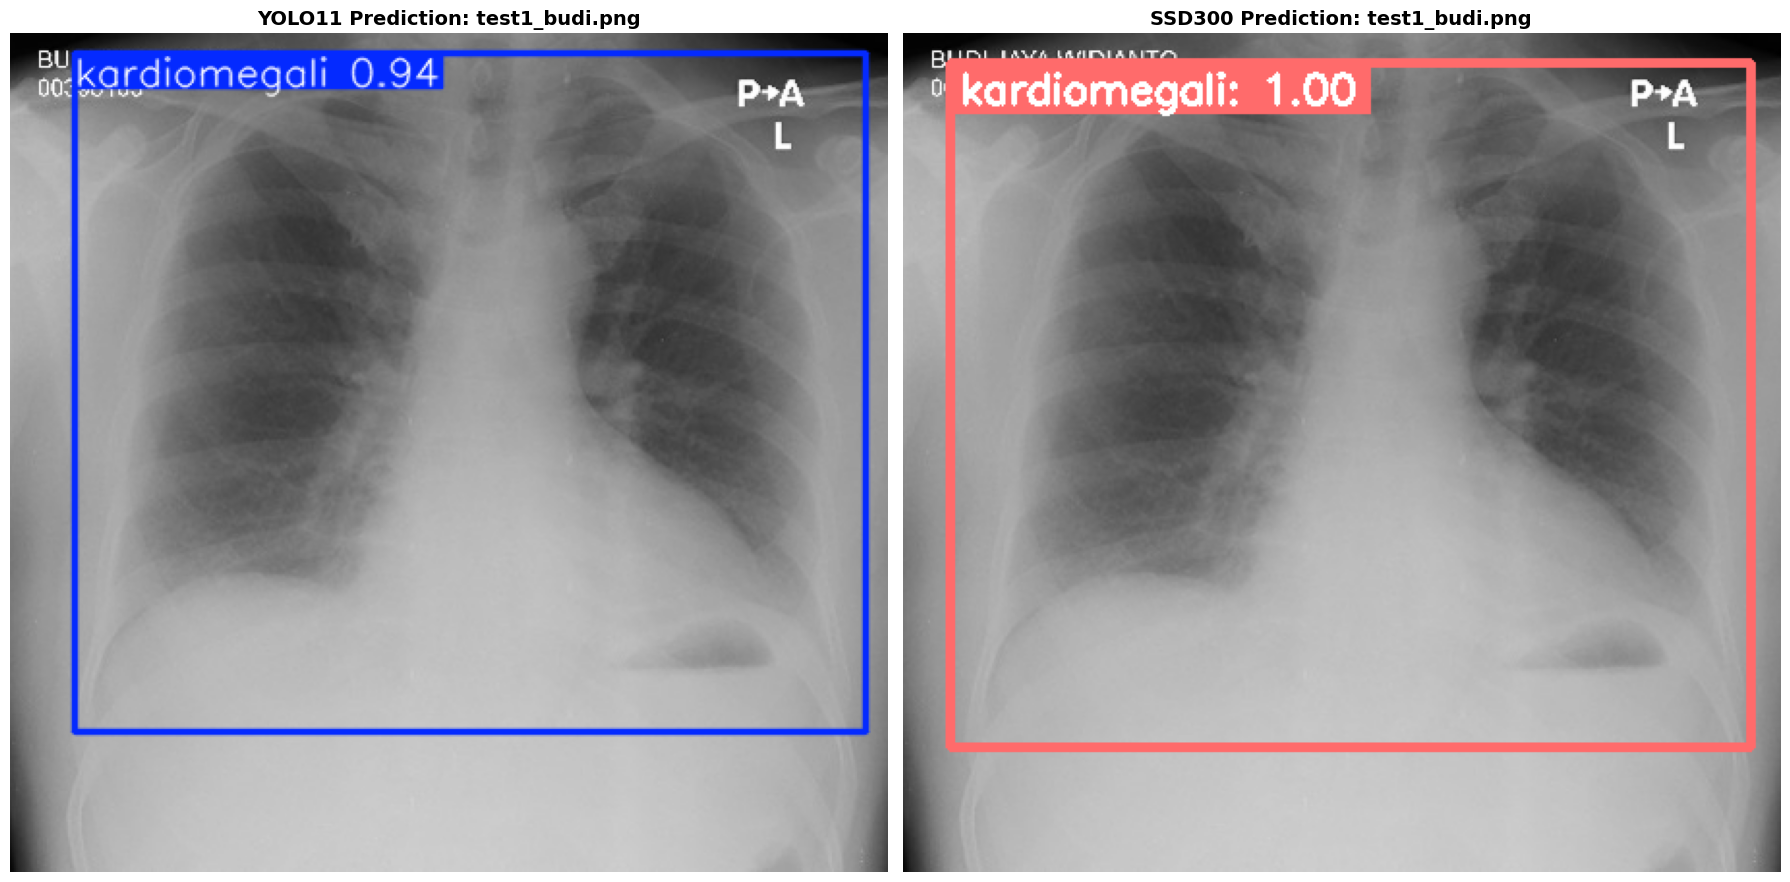


YOLO Detection
[{'class': 'kardiomegali', 'confidence': 0.9381875395774841, 'box': [33.64286804199219, 10.639867782592773, 442.000244140625, 361.0255126953125]}]

SSD Detection
[{'class': 'kardiomegali', 'confidence': 0.9968619346618652, 'box': [24, 15, 438, 369]}]

Gambar 2/10
test2_juan.png


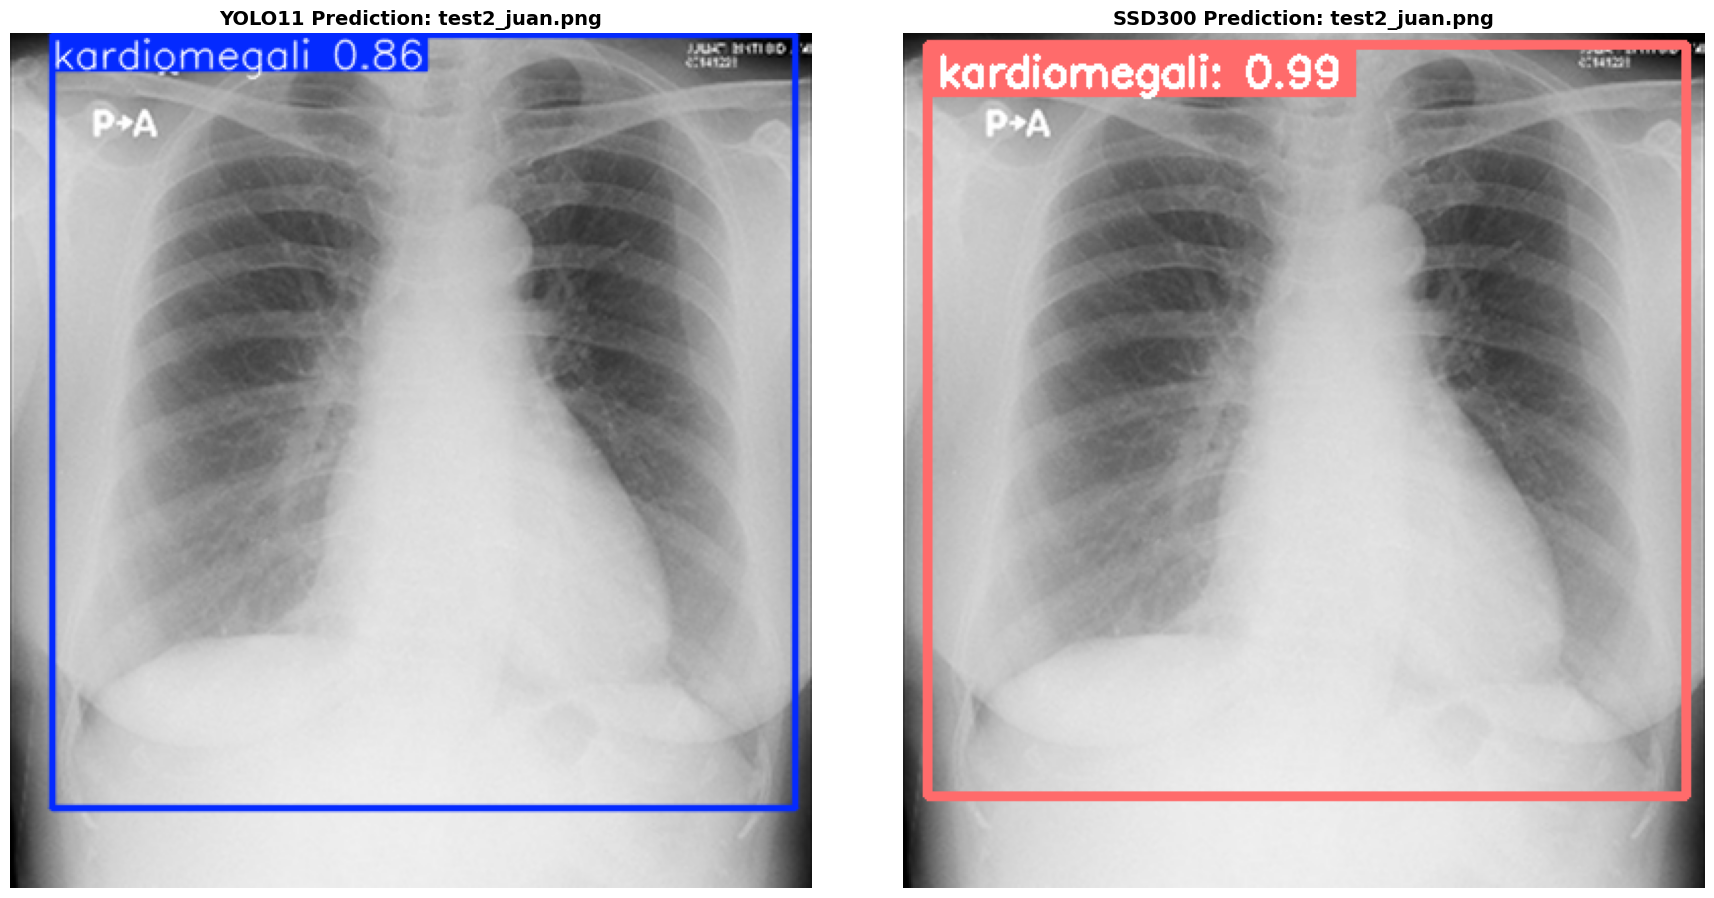


YOLO Detection
[{'class': 'kardiomegali', 'confidence': 0.8620501160621643, 'box': [21.298290252685547, 1.4286599159240723, 398.49920654296875, 393.84765625]}]

SSD Detection
[{'class': 'kardiomegali', 'confidence': 0.9938338994979858, 'box': [12, 6, 397, 387]}]

Gambar 3/10
test3_tiar.png


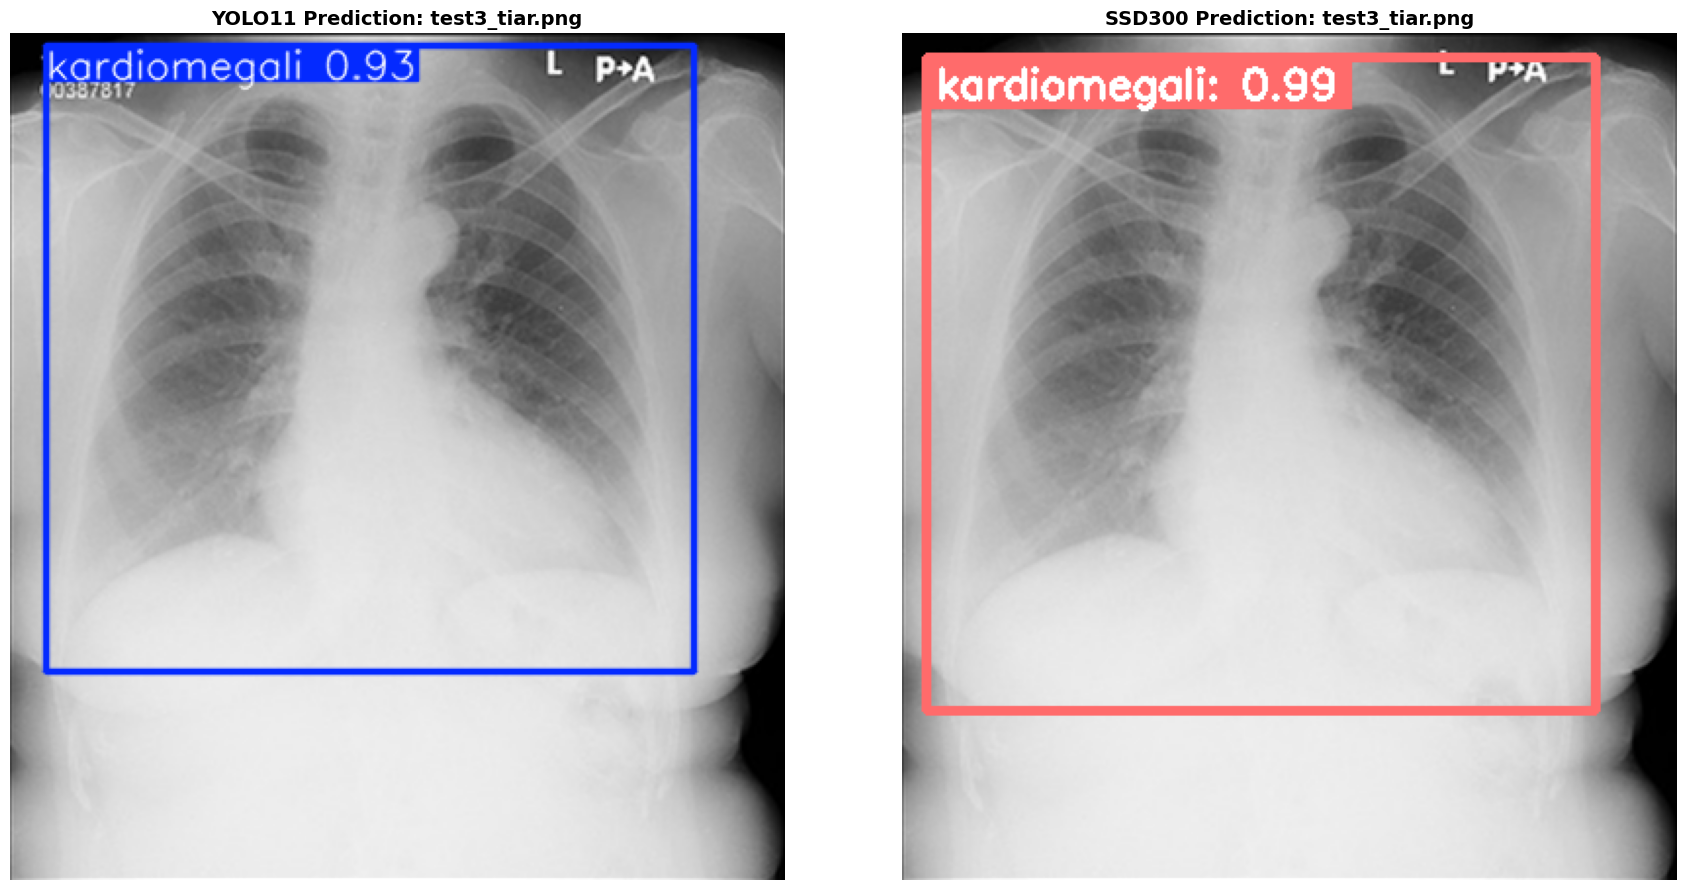


YOLO Detection
[{'class': 'kardiomegali', 'confidence': 0.9261273741722107, 'box': [18.27052116394043, 6.886693954467773, 349.7672424316406, 326.6407165527344]}]

SSD Detection
[{'class': 'kardiomegali', 'confidence': 0.9904388785362244, 'box': [12, 12, 354, 346]}]

Gambar 4/10
test4_yumarlina.png


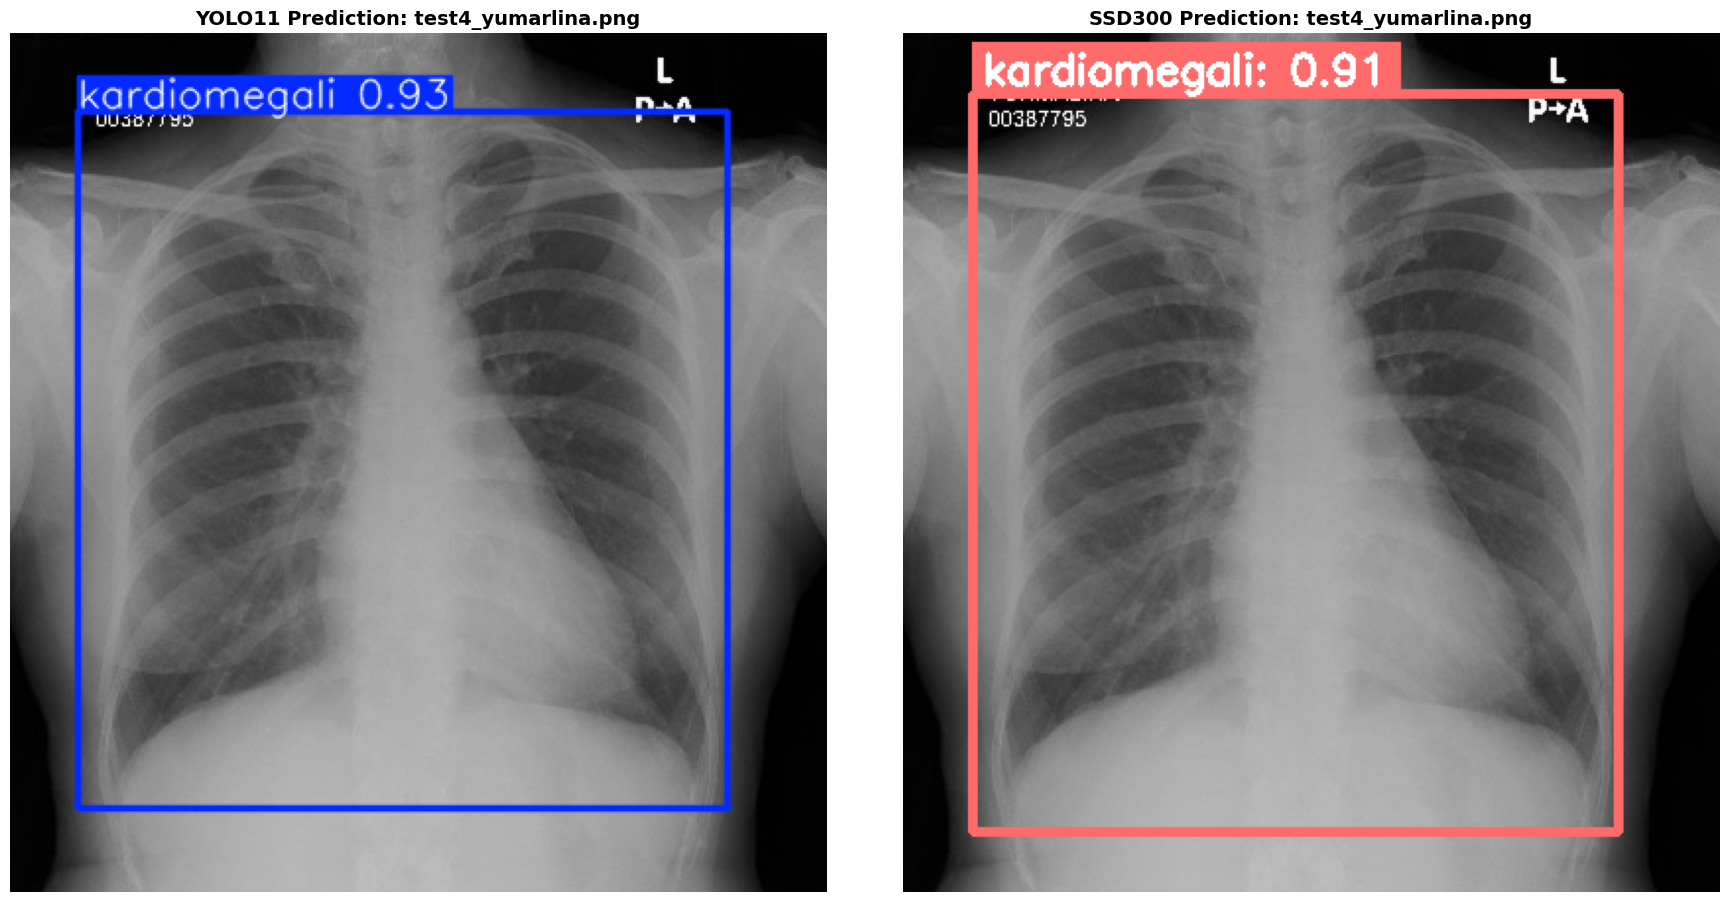


YOLO Detection
[{'class': 'kardiomegali', 'confidence': 0.9259110689163208, 'box': [34.30540084838867, 40.569366455078125, 364.3503723144531, 394.3017272949219]}]

SSD Detection
[{'class': 'kardiomegali', 'confidence': 0.9072240591049194, 'box': [35, 31, 363, 406]}]

Gambar 5/10
test5_zamzimar(old).png


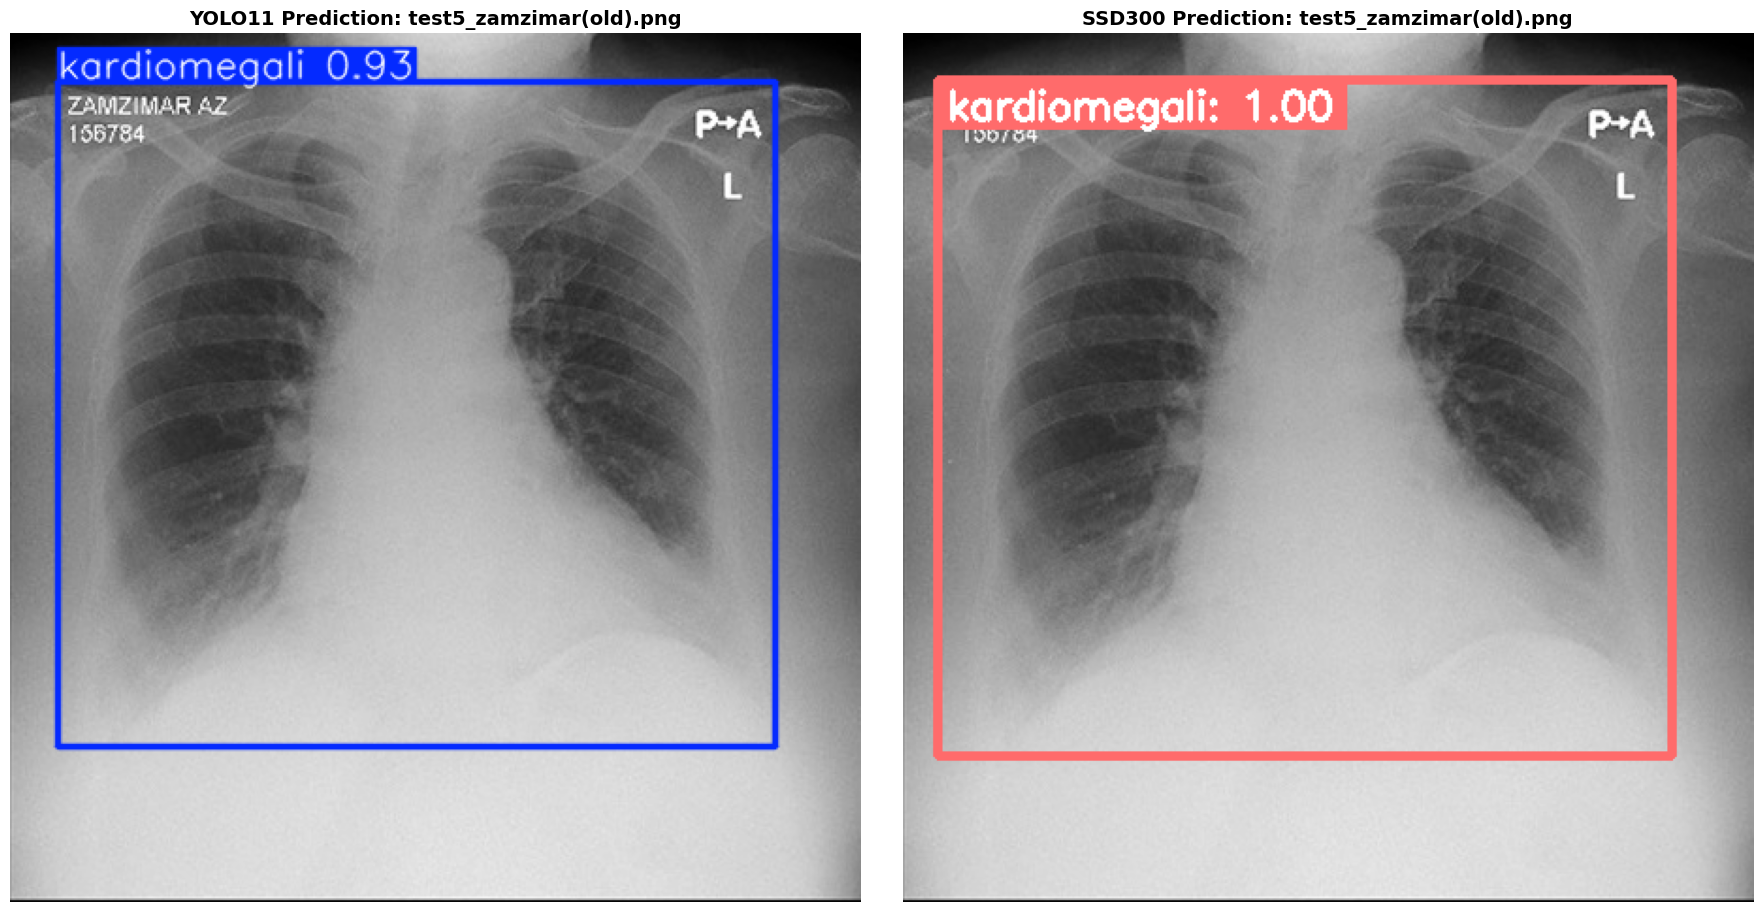


YOLO Detection
[{'class': 'kardiomegali', 'confidence': 0.9292752146720886, 'box': [25.917158126831055, 26.990812301635742, 406.90582275390625, 379.5943298339844]}]

SSD Detection
[{'class': 'kardiomegali', 'confidence': 0.9964596629142761, 'box': [18, 25, 408, 384]}]

Gambar 6/10
test5_zamzimar.jpg


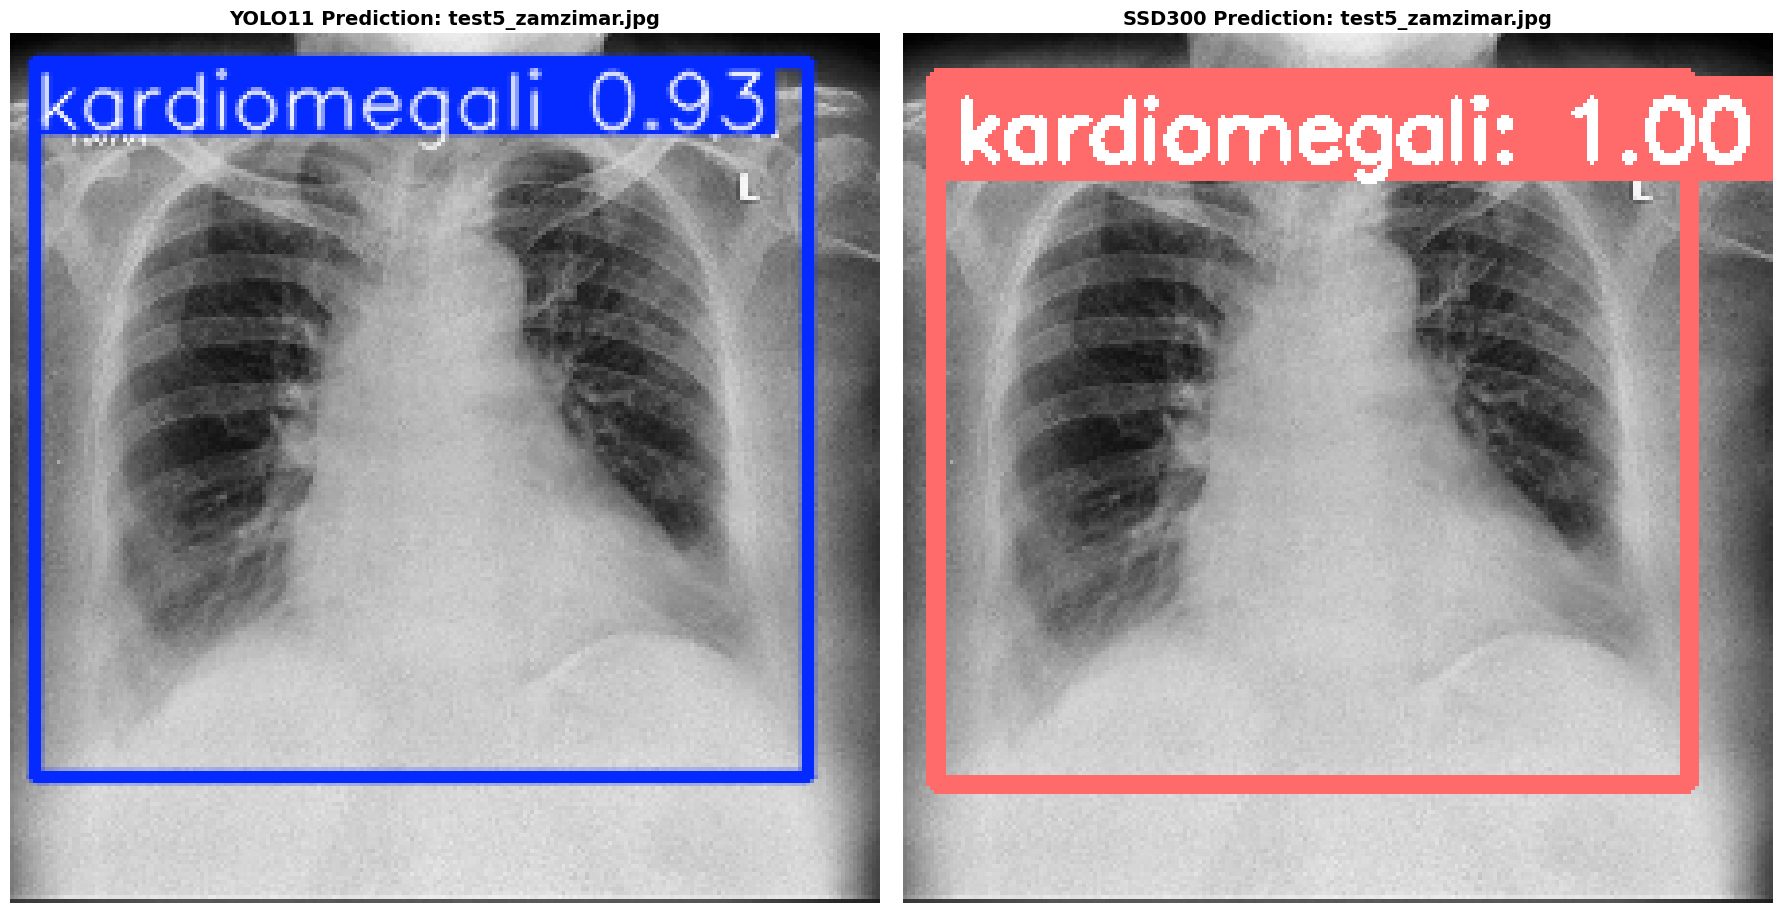


YOLO Detection
[{'class': 'kardiomegali', 'confidence': 0.9313722252845764, 'box': [6.255229949951172, 7.74769401550293, 205.00181579589844, 191.492431640625]}]

SSD Detection
[{'class': 'kardiomegali', 'confidence': 0.9973247051239014, 'box': [8, 11, 202, 193]}]

Gambar 7/10
test6_sitiaminar.png


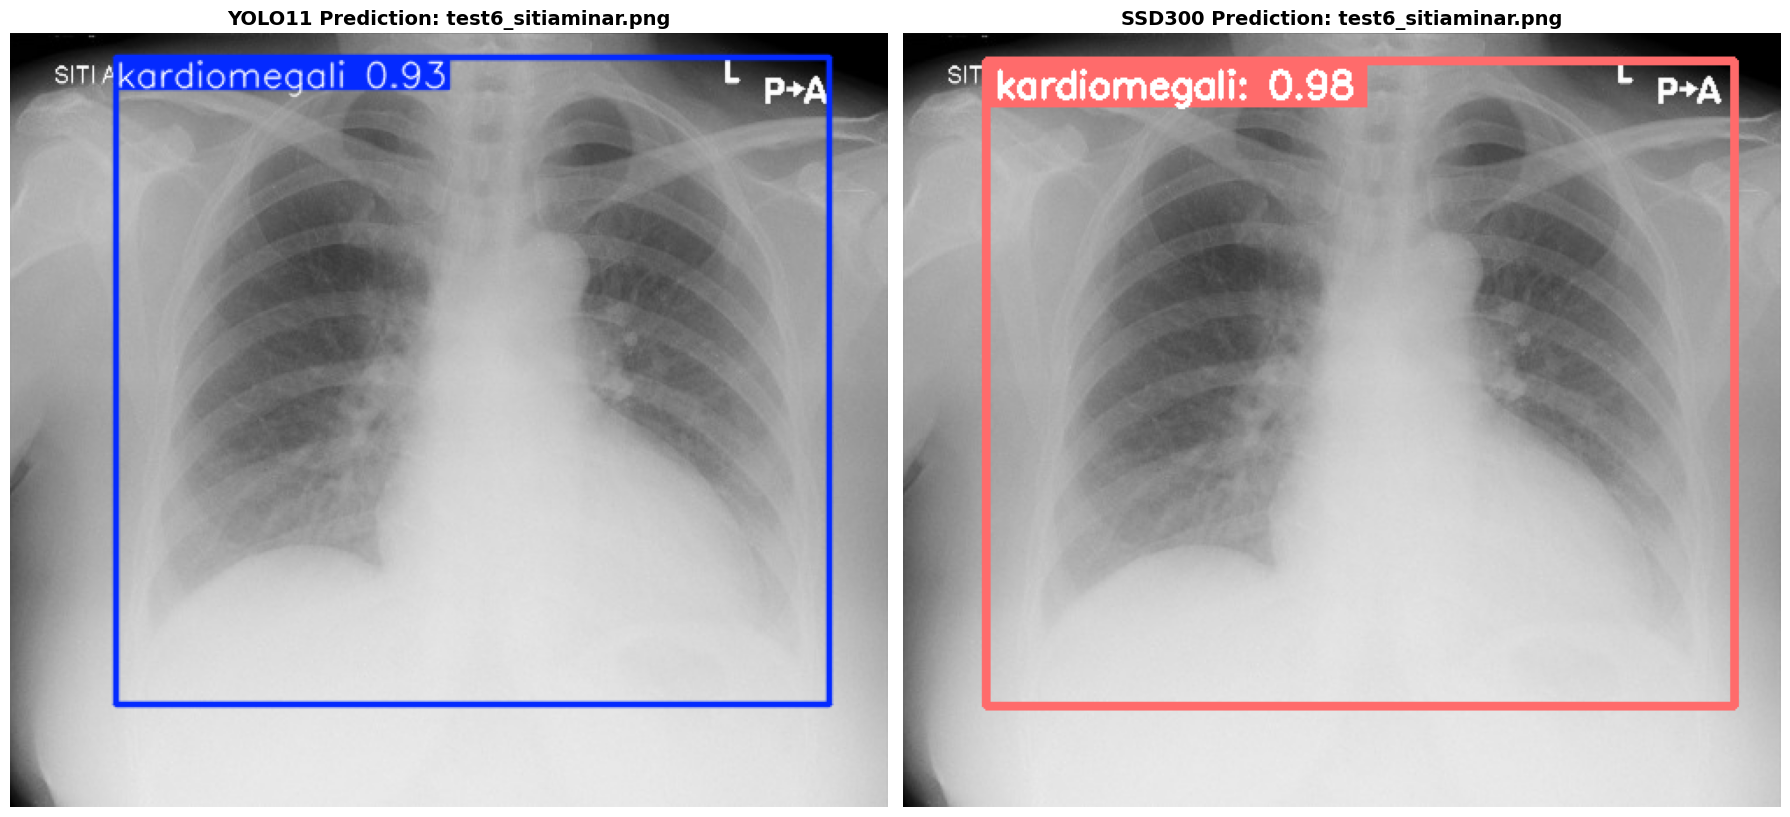


YOLO Detection
[{'class': 'kardiomegali', 'confidence': 0.9306812286376953, 'box': [60.32857131958008, 14.259846687316895, 467.3148498535156, 383.0198974609375]}]

SSD Detection
[{'class': 'kardiomegali', 'confidence': 0.984777569770813, 'box': [47, 16, 474, 384]}]

Gambar 8/10
test7_peronika.png


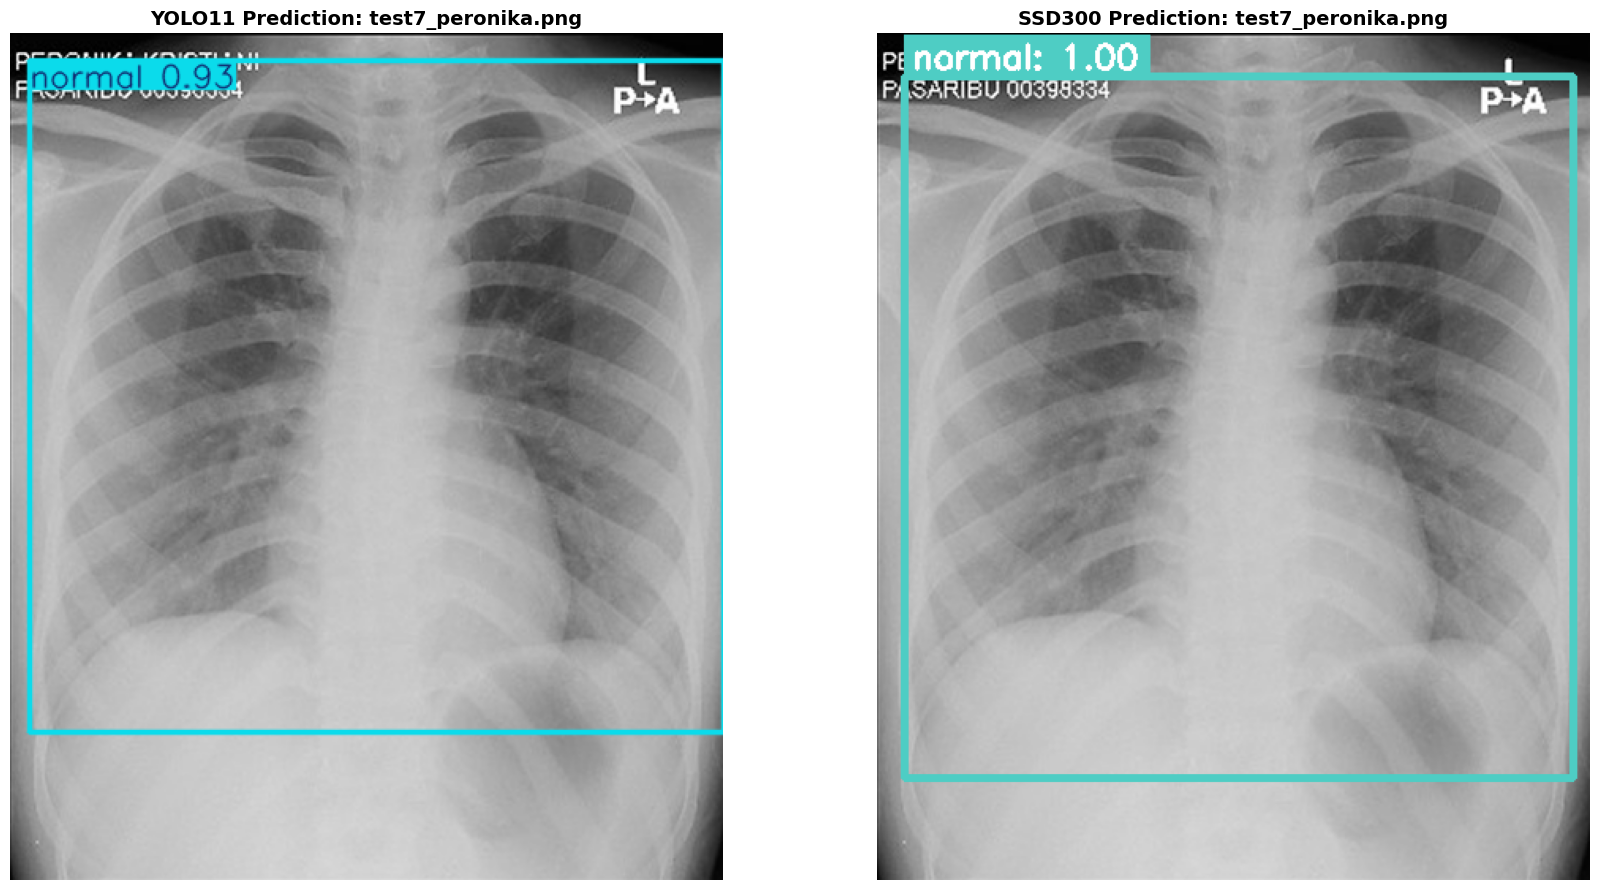


YOLO Detection
[{'class': 'normal', 'confidence': 0.9274505972862244, 'box': [12.523906707763672, 17.14455795288086, 451.0, 442.68804931640625]}]

SSD Detection
[{'class': 'normal', 'confidence': 0.9950366616249084, 'box': [17, 27, 440, 471]}]

Gambar 9/10
test8_dedi.png


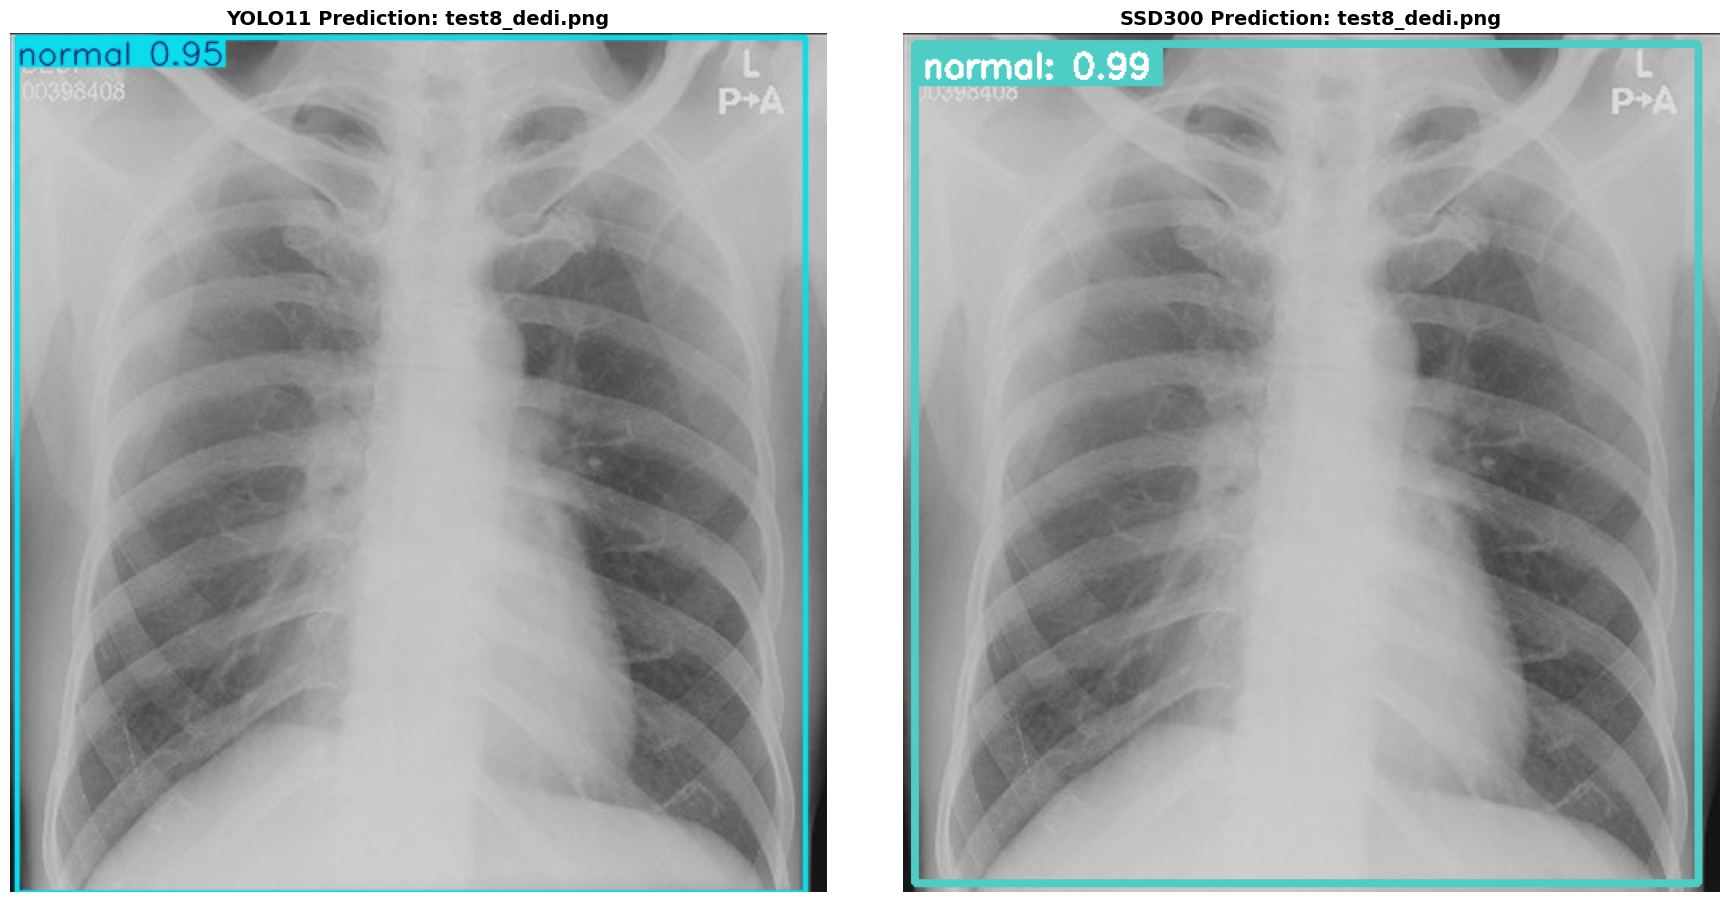


YOLO Detection
[{'class': 'normal', 'confidence': 0.9529439210891724, 'box': [4.3434929847717285, 3.173110008239746, 498.22625732421875, 539.0]}]

SSD Detection
[{'class': 'normal', 'confidence': 0.9856919646263123, 'box': [7, 7, 498, 533]}]

Gambar 10/10
test9_nurhikmah.png


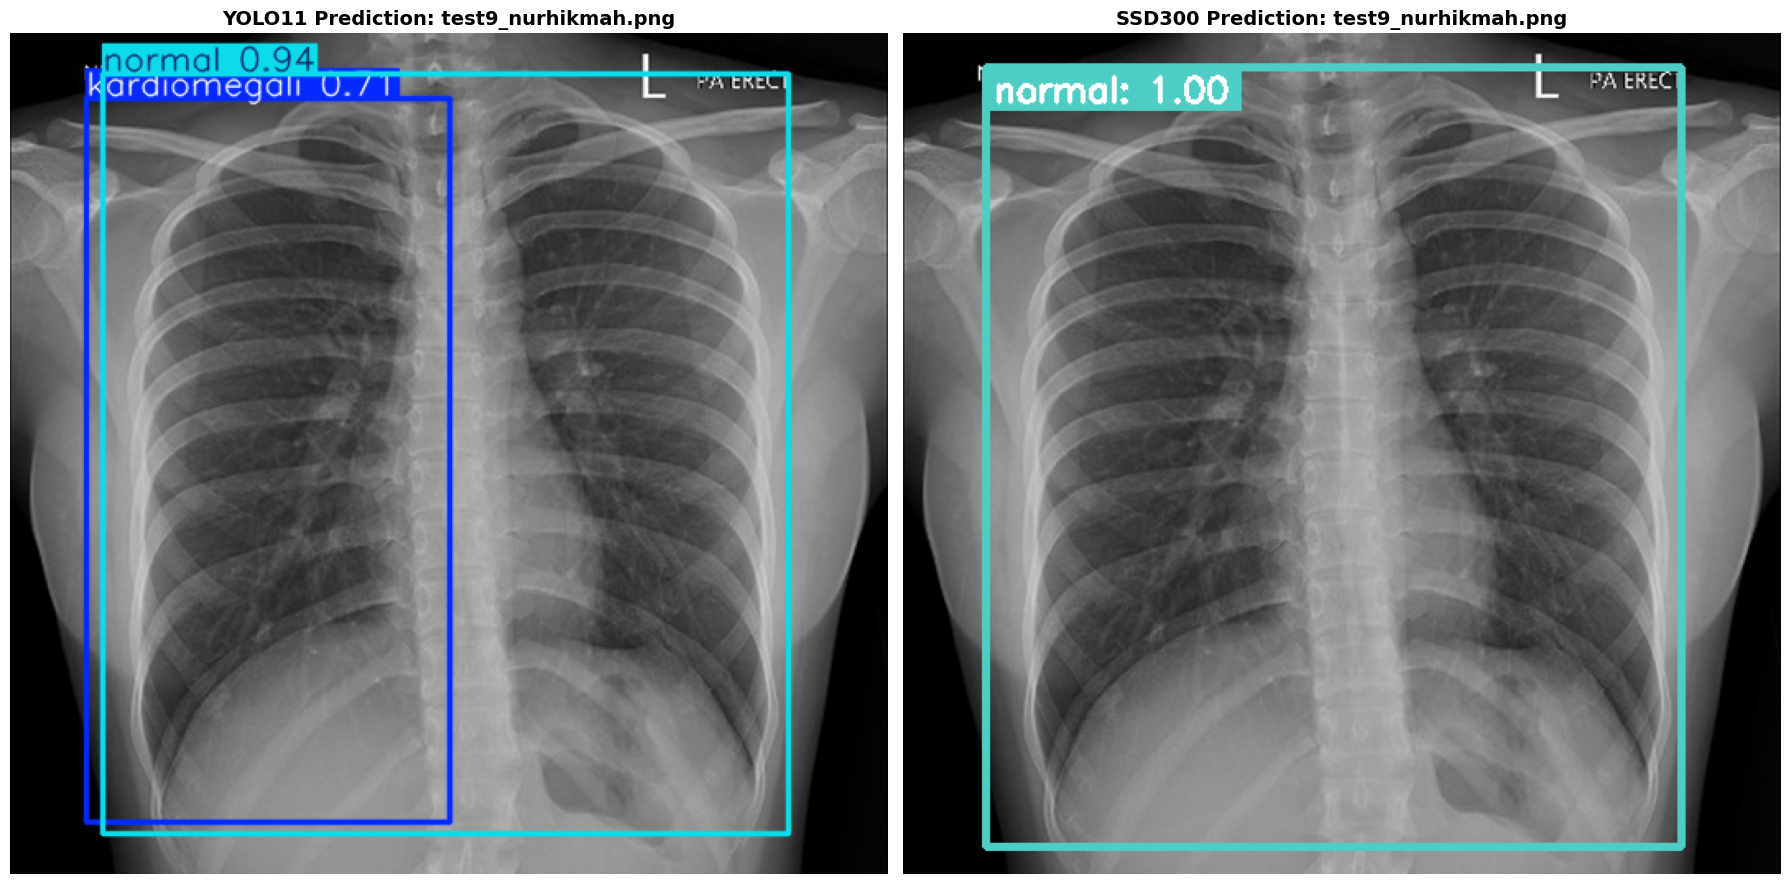


YOLO Detection
[{'class': 'normal', 'confidence': 0.9441248774528503, 'box': [56.19258499145508, 25.098791122436523, 473.5942687988281, 487.26495361328125]}, {'class': 'kardiomegali', 'confidence': 0.7086919546127319, 'box': [46.932830810546875, 40.603084564208984, 267.9355773925781, 480.94049072265625]}]

SSD Detection
[{'class': 'normal', 'confidence': 0.9997275471687317, 'box': [50, 21, 473, 495]}]


In [46]:
# ==========================================================
# INFERENSI SEMUA GAMBAR DALAM FOLDER PREDICT
# ==========================================================

from pathlib import Path

# Folder dataset predict
PREDICT_DIR = Path(
    "/kaggle/input/datasets/iicaadsyd/predict-model-yolo11-ssd/predict"
)

# Pastikan folder ada
if not PREDICT_DIR.exists():
    raise FileNotFoundError(f"Folder tidak ditemukan:\n{PREDICT_DIR}")

# Ambil seluruh gambar
image_files = sorted([
    p for p in PREDICT_DIR.iterdir()
    if p.suffix.lower() in [".png", ".jpg", ".jpeg", ".bmp"]
])

print("="*80)
print(f"Folder : {PREDICT_DIR}")
print(f"Jumlah gambar : {len(image_files)}")
print("="*80)

# Load SSD sekali saja
ssd_model = load_ssd_for_inference()

# Load YOLO sekali saja
yolo_model = YOLO(str(BEST_YOLO_PT))

# Loop seluruh gambar
for i, image_path in enumerate(image_files, start=1):

    print("\n" + "="*100)
    print(f"Gambar {i}/{len(image_files)}")
    print(image_path.name)
    print("="*100)

    hasil = predict_compare(
        image_path=image_path,
        yolo_model=yolo_model,
        ssd_model=ssd_model,
        conf_threshold=0.25
    )

    print("\nYOLO Detection")
    print(hasil["yolo"])

    print("\nSSD Detection")
    print(hasil["ssd"])

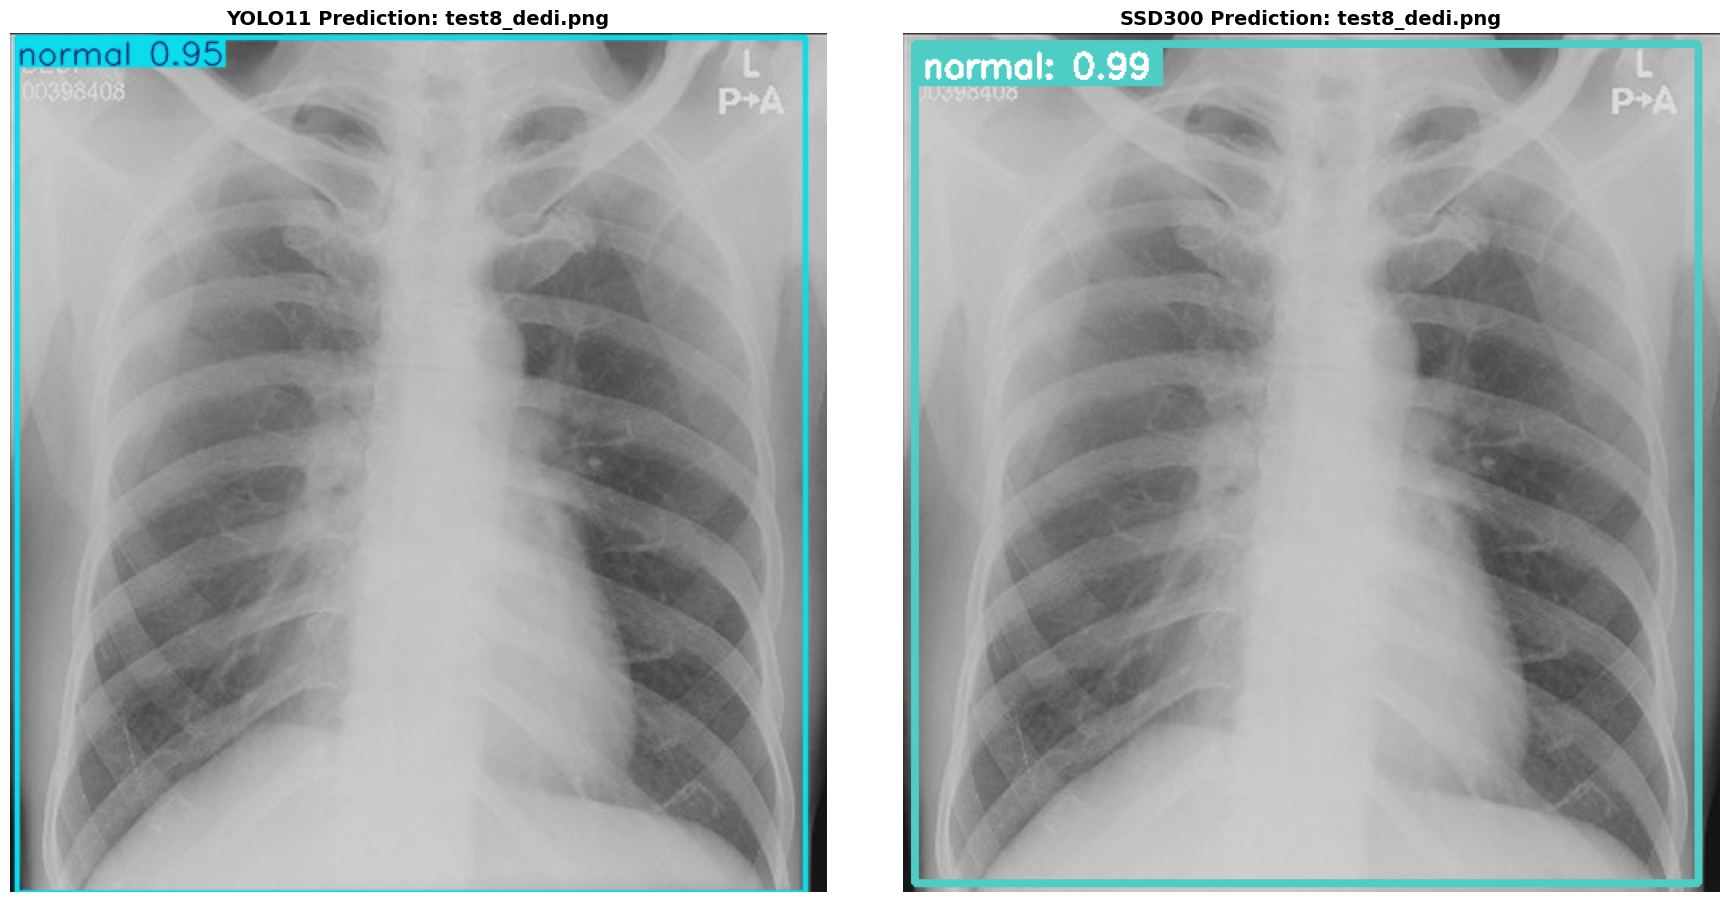


YOLO Detection
[{'class': 'normal', 'confidence': 0.9529439210891724, 'box': [4.3434929847717285, 3.173110008239746, 498.22625732421875, 539.0]}]

SSD Detection
[{'class': 'normal', 'confidence': 0.9856919646263123, 'box': [7, 7, 498, 533]}]


In [48]:
from ultralytics import YOLO

image_path = "/kaggle/input/datasets/iicaadsyd/predict-model-yolo11-ssd/predict/test8_dedi.png"

# Load model
ssd_model = load_ssd_for_inference()
yolo_model = YOLO(str(BEST_YOLO_PT))

hasil = predict_compare(
    image_path=image_path,
    yolo_model=yolo_model,
    ssd_model=ssd_model,
    conf_threshold=0.25
)

print("\nYOLO Detection")
print(hasil["yolo"])

print("\nSSD Detection")
print(hasil["ssd"])

Inference Image
yohannes.PNG


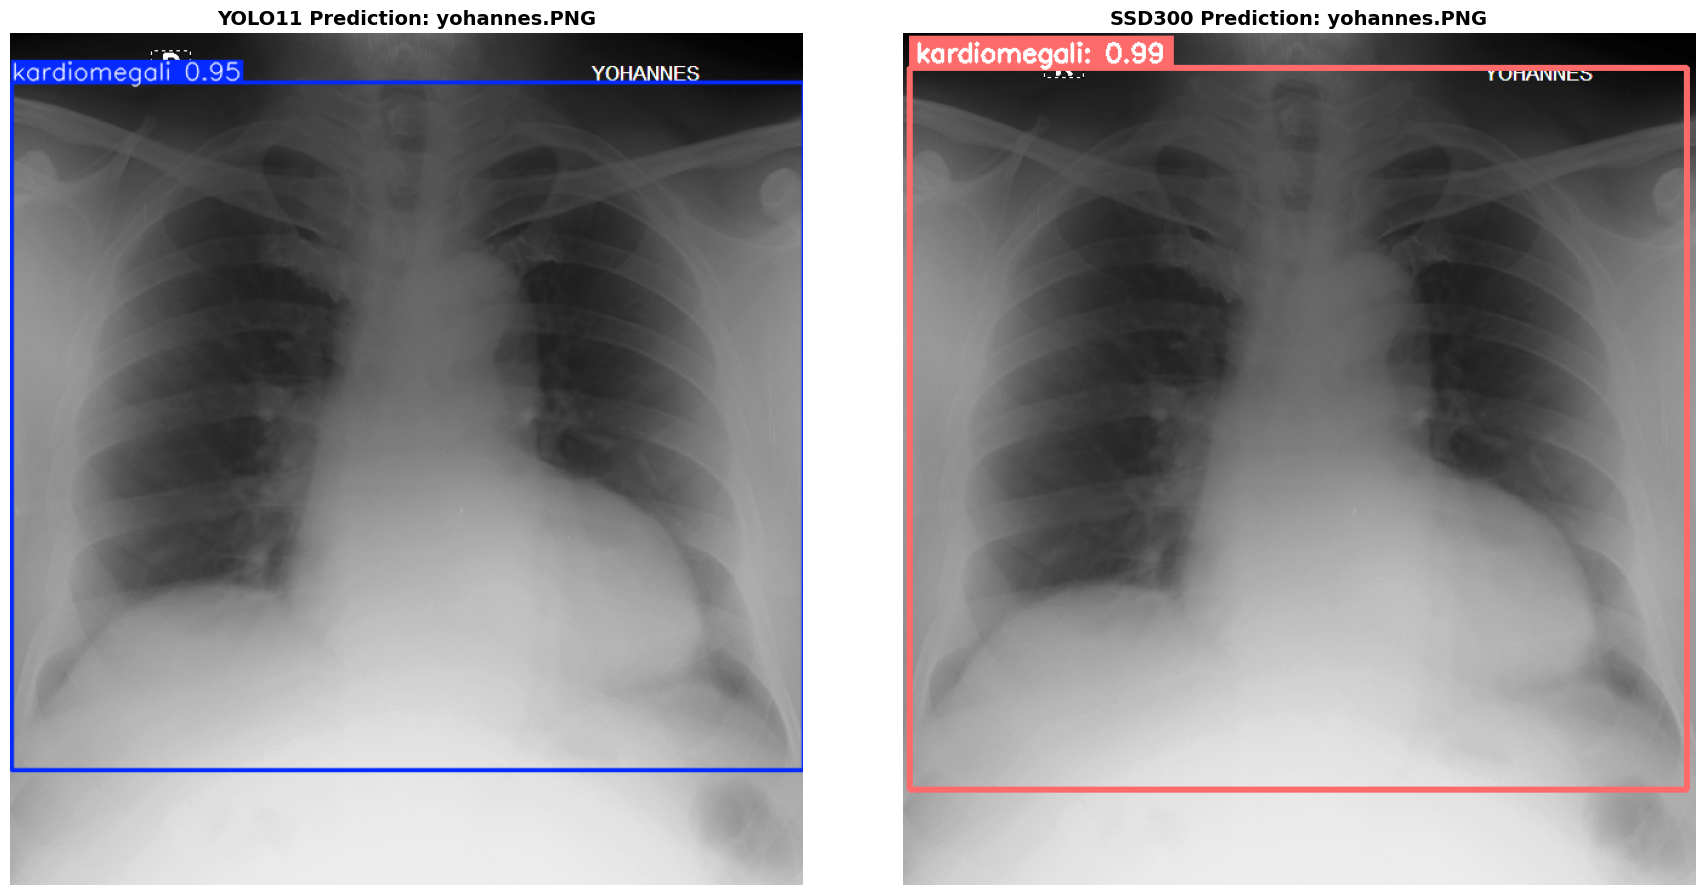


YOLOv11s Detection
1.
   Class      : kardiomegali
   Confidence : 0.9473
   BoundingBox: [1.2, 41.9, 653.0, 607.7]

SSD300-VGG16 Detection
1.
   Class      : kardiomegali
   Confidence : 0.9945
   BoundingBox: [5, 29, 645, 623]



In [50]:
# ==========================================================
# INFERENSI SATU GAMBAR
# ==========================================================

from ultralytics import YOLO
from pathlib import Path

IMAGE_PATH = Path(
    "/kaggle/input/datasets/iicaadsyd/inference/inference/yohannes.PNG"
)

print("="*80)
print("Inference Image")
print(IMAGE_PATH.name)
print("="*80)

# Load model sekali
yolo_model = YOLO(str(BEST_YOLO_PT))
ssd_model = load_ssd_for_inference()

hasil = predict_compare(
    image_path=IMAGE_PATH,
    yolo_model=yolo_model,
    ssd_model=ssd_model,
    conf_threshold=0.25
)

print("\n" + "="*80)
print("YOLOv11s Detection")
print("="*80)

if len(hasil["yolo"]) == 0:
    print("Tidak ada objek terdeteksi.")
else:
    for i, det in enumerate(hasil["yolo"], 1):
        print(f"{i}.")
        print(f"   Class      : {det['class']}")
        print(f"   Confidence : {det['confidence']:.4f}")
        print(f"   BoundingBox: {[round(v,1) for v in det['box']]}")
        print()

print("="*80)
print("SSD300-VGG16 Detection")
print("="*80)

if len(hasil["ssd"]) == 0:
    print("Tidak ada objek terdeteksi.")
else:
    for i, det in enumerate(hasil["ssd"], 1):
        print(f"{i}.")
        print(f"   Class      : {det['class']}")
        print(f"   Confidence : {det['confidence']:.4f}")
        print(f"   BoundingBox: {[round(v,1) for v in det['box']]}")
        print()

Inference Image
mardial.PNG


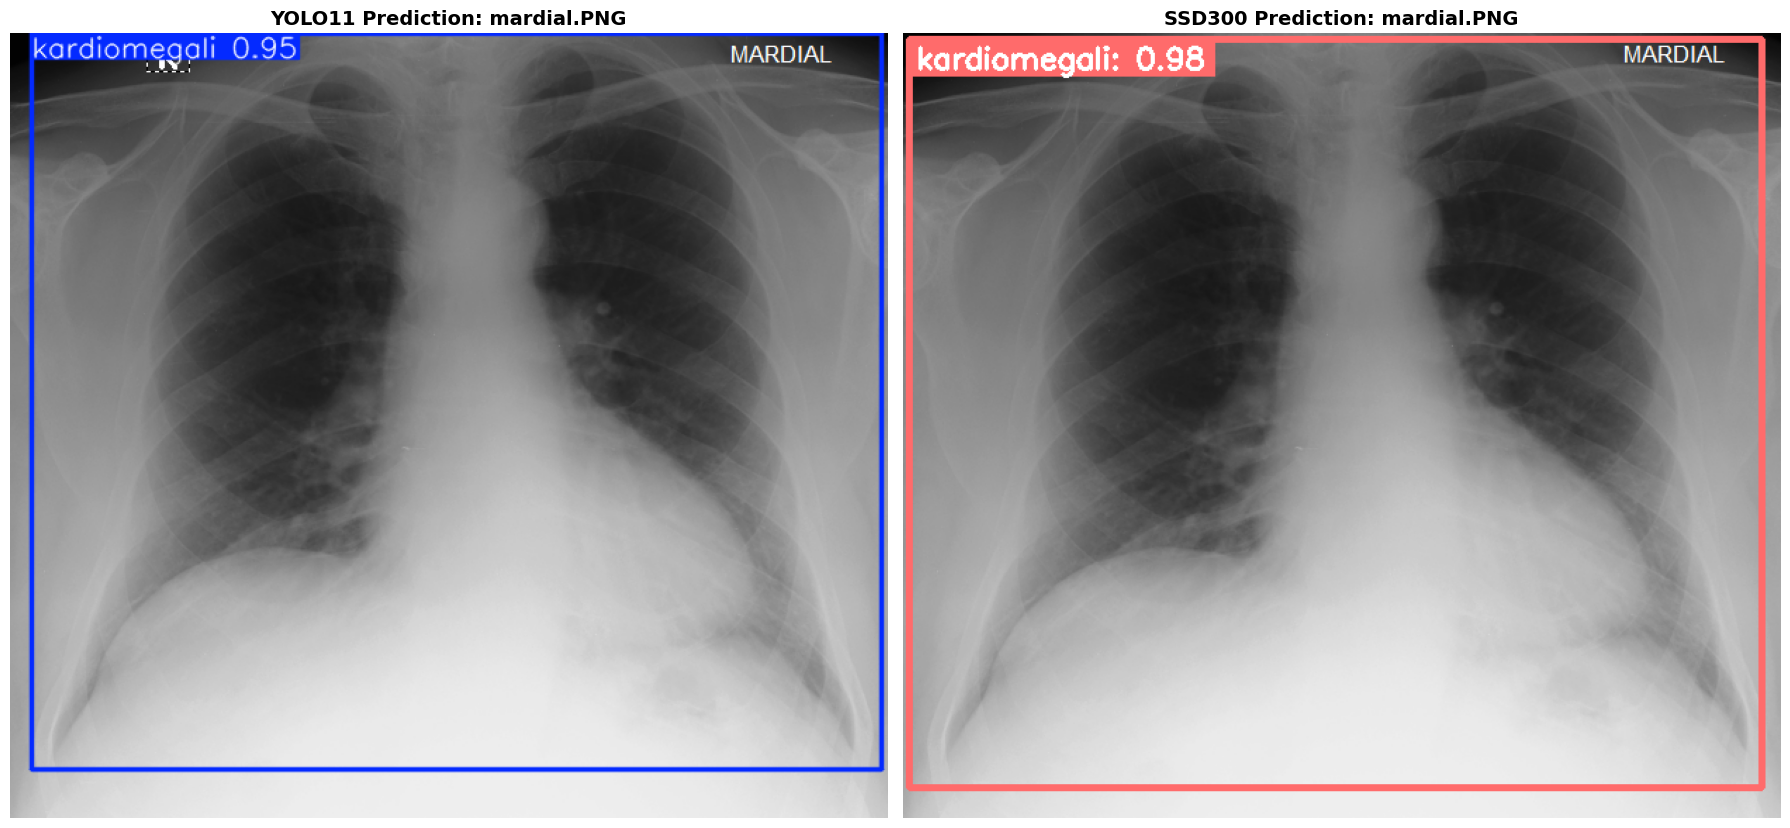


YOLOv11s Detection
1.
   Class      : kardiomegali
   Confidence : 0.9494
   BoundingBox: [15.9, 0.0, 619.4, 523.1]

SSD300-VGG16 Detection
1.
   Class      : kardiomegali
   Confidence : 0.9832
   BoundingBox: [4, 4, 610, 536]



In [51]:
# ==========================================================
# INFERENSI SATU GAMBAR
# ==========================================================

from ultralytics import YOLO
from pathlib import Path

IMAGE_PATH = Path(
    "/kaggle/input/datasets/iicaadsyd/inference/inference/mardial.PNG"
)

print("="*80)
print("Inference Image")
print(IMAGE_PATH.name)
print("="*80)

# Load model sekali
yolo_model = YOLO(str(BEST_YOLO_PT))
ssd_model = load_ssd_for_inference()

hasil = predict_compare(
    image_path=IMAGE_PATH,
    yolo_model=yolo_model,
    ssd_model=ssd_model,
    conf_threshold=0.25
)

print("\n" + "="*80)
print("YOLOv11s Detection")
print("="*80)

if len(hasil["yolo"]) == 0:
    print("Tidak ada objek terdeteksi.")
else:
    for i, det in enumerate(hasil["yolo"], 1):
        print(f"{i}.")
        print(f"   Class      : {det['class']}")
        print(f"   Confidence : {det['confidence']:.4f}")
        print(f"   BoundingBox: {[round(v,1) for v in det['box']]}")
        print()

print("="*80)
print("SSD300-VGG16 Detection")
print("="*80)

if len(hasil["ssd"]) == 0:
    print("Tidak ada objek terdeteksi.")
else:
    for i, det in enumerate(hasil["ssd"], 1):
        print(f"{i}.")
        print(f"   Class      : {det['class']}")
        print(f"   Confidence : {det['confidence']:.4f}")
        print(f"   BoundingBox: {[round(v,1) for v in det['box']]}")
        print()